# Flash drought manuscript v5 — cleaned figure notebook

This notebook retains the figure versions visually matched to the embedded figures in **FD manuscript_v5.docx**. It removes superseded plotting experiments while preserving their necessary calculations. Original scientific calculations and plotting parameters are retained; reviewer-requested new analyses are not implemented here.

Run **Setup**, then each figure section's preparation and plotting cells in order. Figure sections are arranged in manuscript order. Cell provenance below uses **zero-based original notebook indices** (add 1 for the ordinal position in the original notebook, counting markdown and empty cells).

**Limits:** raw Google Drive GeoTIFF/CSV inputs were not supplied with the three reviewed files. This copy has been checked statically, not run against your research data. Saved outputs were cleared to avoid presenting old images as fresh results. Figures 1–4 include panel-generation code but not all manuscript layout/legend/inset assembly. Existing save paths and overwrite behavior remain as in the original; use a copy of your Drive data/output folder if you need to preserve prior exports.

See `Flash_drought_cleanup_notes.md` for the figure mapping, removed cells, input files, and existing issues to review separately.

## Setup
Install dependencies before imports (the original Cartopy installation was after its first use). Mount Drive once. The install cell does not pin historical package versions, which were not recorded in the source notebook.


In [ ]:
%pip install -q rasterio cartopy "seaborn>=0.13" scipy


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 26.7 MB/s eta 0:00:00


In [ ]:
import os
import glob
import re
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
import seaborn as sns
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
from rasterio.plot import plotting_extent
from google.colab import drive

drive.mount('/content/drive')
DATA_DIR = '/content/drive/MyDrive/GEE_Exports/'


/tmp/ipykernel_677/1384365548.py:10: DeprecationWarning: The LONGITUDE_FORMATTER module-level attribute was deprecated in Cartopy 0.26. Use LongitudeFormatter instead.
  from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
/tmp/ipykernel_677/1384365548.py:10: DeprecationWarning: The LATITUDE_FORMATTER module-level attribute was deprecated in Cartopy 0.26. Use LatitudeFormatter instead.
  from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER


Mounted at /content/drive


## Figure 1 — land-cover map base
Original cell 27. The manuscript inset, land-cover legend and final composition are not generated by this cell. The GeoTIFF must already contain rendered RGB channels.


🎉 Success! High-resolution map with gridlines saved to Drive:
/content/drive/MyDrive/Grouped_LandCover_Map_Final.png


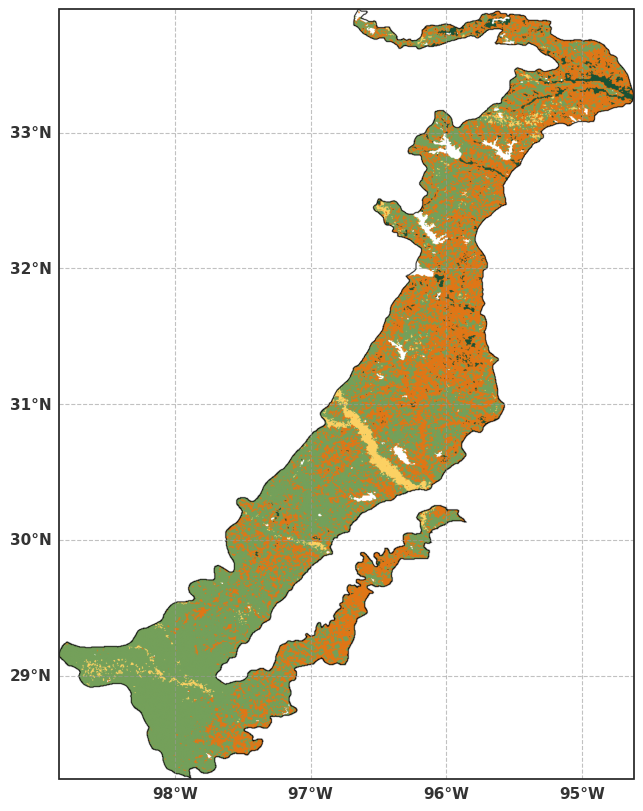

In [ ]:
# Explicit style formerly inherited from the annual plotting section.
sns.set_theme(style="ticks")

# 2. Specify paths - Use the file name exported from Google Earth Engine
tiff_path = '/content/drive/MyDrive/Grouped_LandCover_Map.tif'
output_png = '/content/drive/MyDrive/Grouped_LandCover_Map_Final.png'

# 3. Read the geospatial dataset
with rasterio.open(tiff_path) as src:
    # plotting_extent automatically extracts the Lat/Lon bounding box bounds from metadata
    img_extent = plotting_extent(src)
    img_data = src.read()  # Reads pre-rendered RGB channels (Bands, Height, Width)

# 4. Reorder array layout from GIS structure to standard image format (Height, Width, Bands)
# and normalize color value ranges from 0-255 down to 0.0-1.0 for matplotlib compatibility
rgb_image = img_data.transpose(1, 2, 0) / 255.0

# =========================================================================
# 5. GENERATE CARTOGRAPHIC PRESENTATION FRAME
# =========================================================================
fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.PlateCarree()})

# Draw map matching its explicit spatial geographic bounds
# Note: 'origin=upper' ensures the map layout is not flipped upside-down
ax.imshow(rgb_image, extent=img_extent, transform=ccrs.PlateCarree(), origin='upper')

# =========================================================================
# 6. AUTOMATE LATITUDE & LONGITUDE LABEL GRIDLINES
# =========================================================================
gl = ax.gridlines(draw_labels=True, linestyle='--', color='#999999', alpha=0.6, linewidth=0.8)

# Clean style adjustments to match a professional manuscript layout
gl.top_labels = False    # Disable top coordinates
gl.right_labels = False  # Disable right coordinates
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

# Font specifications for readability
gl.xlabel_style = {'size': 11, 'weight': 'bold', 'color': '#333333'}
gl.ylabel_style = {'size': 11, 'weight': 'bold', 'color': '#333333'}

# =========================================================================
# 7. SAVE HIGH-RESOLUTION COMPACT PNG
# =========================================================================
# bbox_inches='tight' strips all dead margins so it drops cleanly into PowerPoint
plt.savefig(output_png, dpi=300, bbox_inches='tight', pad_inches=0.1)
print(f"🎉 Success! High-resolution map with gridlines saved to Drive:\n{output_png}")

plt.show()

## Figure 2 — five mean annual map panels
Original cells 28–32. These read already-rendered RGB GeoTIFFs; they do not calculate annual means or create the manuscript legends/panel assembly.


🎉 Success! High-resolution map with gridlines saved to Drive:
/content/drive/MyDrive/PET_Final.png


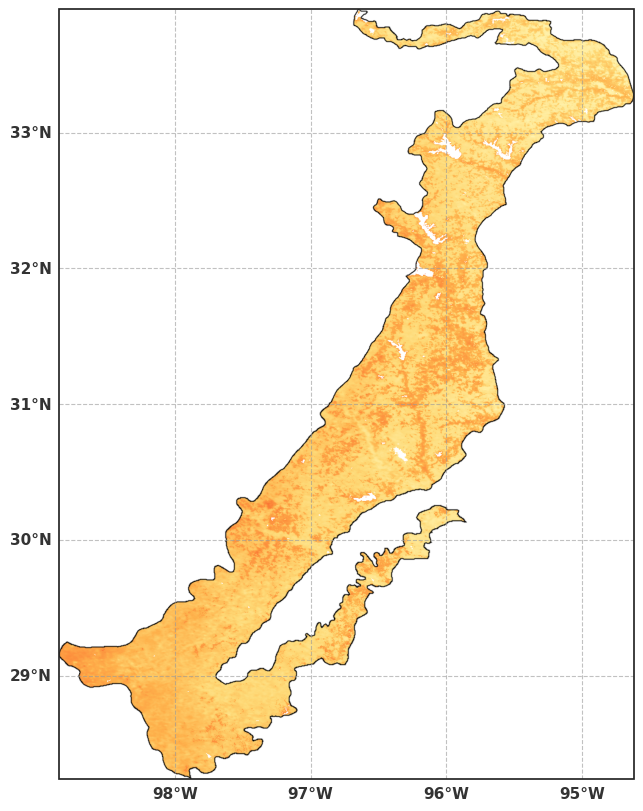

In [ ]:
# 2. Specify paths - Use the file name exported from Google Earth Engine
tiff_path = '/content/drive/MyDrive/PET.tif'
output_png = '/content/drive/MyDrive/PET_Final.png'

# 3. Read the geospatial dataset
with rasterio.open(tiff_path) as src:
    # plotting_extent automatically extracts the Lat/Lon bounding box bounds from metadata
    img_extent = plotting_extent(src)
    img_data = src.read()  # Reads pre-rendered RGB channels (Bands, Height, Width)

# 4. Reorder array layout from GIS structure to standard image format (Height, Width, Bands)
# and normalize color value ranges from 0-255 down to 0.0-1.0 for matplotlib compatibility
rgb_image = img_data.transpose(1, 2, 0) / 255.0

# =========================================================================
# 5. GENERATE CARTOGRAPHIC PRESENTATION FRAME
# =========================================================================
fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.PlateCarree()})

# Draw map matching its explicit spatial geographic bounds
# Note: 'origin=upper' ensures the map layout is not flipped upside-down
ax.imshow(rgb_image, extent=img_extent, transform=ccrs.PlateCarree(), origin='upper')

# =========================================================================
# 6. AUTOMATE LATITUDE & LONGITUDE LABEL GRIDLINES
# =========================================================================
gl = ax.gridlines(draw_labels=True, linestyle='--', color='#999999', alpha=0.6, linewidth=0.8)

# Clean style adjustments to match a professional manuscript layout
gl.top_labels = False    # Disable top coordinates
gl.right_labels = False  # Disable right coordinates
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

# Font specifications for readability
gl.xlabel_style = {'size': 11, 'weight': 'bold', 'color': '#333333'}
gl.ylabel_style = {'size': 11, 'weight': 'bold', 'color': '#333333'}

# =========================================================================
# 7. SAVE HIGH-RESOLUTION COMPACT PNG
# =========================================================================
# bbox_inches='tight' strips all dead margins so it drops cleanly into PowerPoint
plt.savefig(output_png, dpi=300, bbox_inches='tight', pad_inches=0.1)
print(f"🎉 Success! High-resolution map with gridlines saved to Drive:\n{output_png}")

plt.show()

🎉 Success! High-resolution map with gridlines saved to Drive:
/content/drive/MyDrive/AET_Final.png


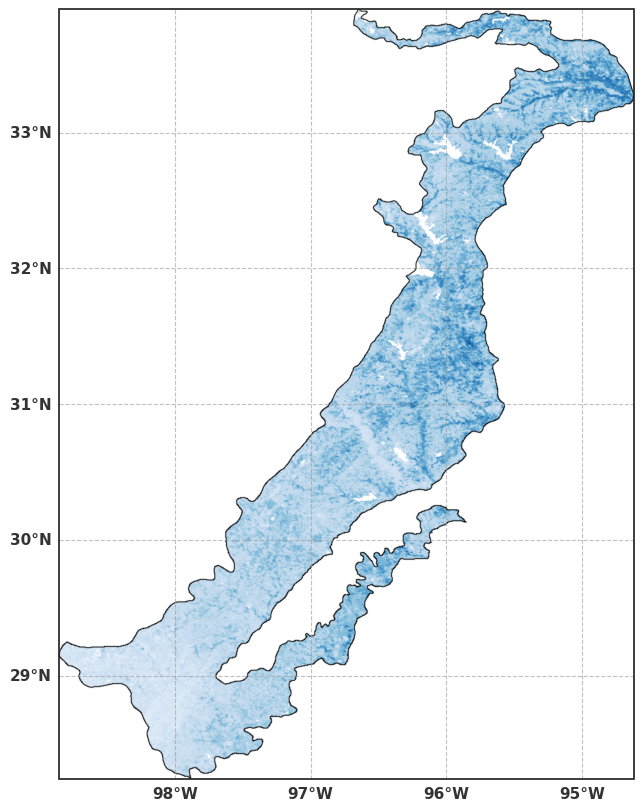

In [ ]:
# 2. Specify paths - Use the file name exported from Google Earth Engine
tiff_path = '/content/drive/MyDrive/AET.tif'
output_png = '/content/drive/MyDrive/AET_Final.png'

# 3. Read the geospatial dataset
with rasterio.open(tiff_path) as src:
    # plotting_extent automatically extracts the Lat/Lon bounding box bounds from metadata
    img_extent = plotting_extent(src)
    img_data = src.read()  # Reads pre-rendered RGB channels (Bands, Height, Width)

# 4. Reorder array layout from GIS structure to standard image format (Height, Width, Bands)
# and normalize color value ranges from 0-255 down to 0.0-1.0 for matplotlib compatibility
rgb_image = img_data.transpose(1, 2, 0) / 255.0

# =========================================================================
# 5. GENERATE CARTOGRAPHIC PRESENTATION FRAME
# =========================================================================
fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.PlateCarree()})

# Draw map matching its explicit spatial geographic bounds
# Note: 'origin=upper' ensures the map layout is not flipped upside-down
ax.imshow(rgb_image, extent=img_extent, transform=ccrs.PlateCarree(), origin='upper')

# =========================================================================
# 6. AUTOMATE LATITUDE & LONGITUDE LABEL GRIDLINES
# =========================================================================
gl = ax.gridlines(draw_labels=True, linestyle='--', color='#999999', alpha=0.6, linewidth=0.8)

# Clean style adjustments to match a professional manuscript layout
gl.top_labels = False    # Disable top coordinates
gl.right_labels = False  # Disable right coordinates
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

# Font specifications for readability
gl.xlabel_style = {'size': 11, 'weight': 'bold', 'color': '#333333'}
gl.ylabel_style = {'size': 11, 'weight': 'bold', 'color': '#333333'}

# =========================================================================
# 7. SAVE HIGH-RESOLUTION COMPACT PNG
# =========================================================================
# bbox_inches='tight' strips all dead margins so it drops cleanly into PowerPoint
plt.savefig(output_png, dpi=300, bbox_inches='tight', pad_inches=0.1)
print(f"🎉 Success! High-resolution map with gridlines saved to Drive:\n{output_png}")

plt.show()

🎉 Success! High-resolution map with gridlines saved to Drive:
/content/drive/MyDrive/ESR_Final.png


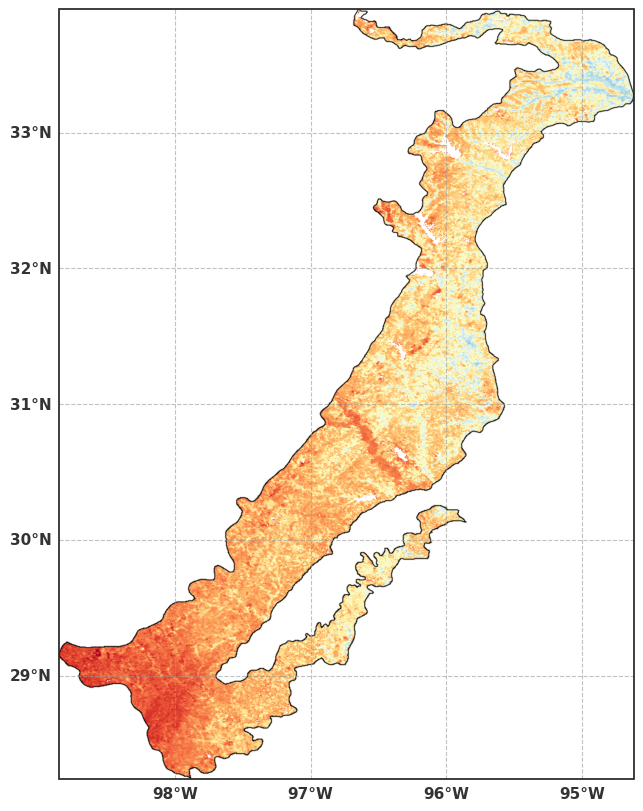

In [ ]:
# 2. Specify paths - Use the file name exported from Google Earth Engine
tiff_path = '/content/drive/MyDrive/ESR.tif'
output_png = '/content/drive/MyDrive/ESR_Final.png'

# 3. Read the geospatial dataset
with rasterio.open(tiff_path) as src:
    # plotting_extent automatically extracts the Lat/Lon bounding box bounds from metadata
    img_extent = plotting_extent(src)
    img_data = src.read()  # Reads pre-rendered RGB channels (Bands, Height, Width)

# 4. Reorder array layout from GIS structure to standard image format (Height, Width, Bands)
# and normalize color value ranges from 0-255 down to 0.0-1.0 for matplotlib compatibility
rgb_image = img_data.transpose(1, 2, 0) / 255.0

# =========================================================================
# 5. GENERATE CARTOGRAPHIC PRESENTATION FRAME
# =========================================================================
fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.PlateCarree()})

# Draw map matching its explicit spatial geographic bounds
# Note: 'origin=upper' ensures the map layout is not flipped upside-down
ax.imshow(rgb_image, extent=img_extent, transform=ccrs.PlateCarree(), origin='upper')

# =========================================================================
# 6. AUTOMATE LATITUDE & LONGITUDE LABEL GRIDLINES
# =========================================================================
gl = ax.gridlines(draw_labels=True, linestyle='--', color='#999999', alpha=0.6, linewidth=0.8)

# Clean style adjustments to match a professional manuscript layout
gl.top_labels = False    # Disable top coordinates
gl.right_labels = False  # Disable right coordinates
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

# Font specifications for readability
gl.xlabel_style = {'size': 11, 'weight': 'bold', 'color': '#333333'}
gl.ylabel_style = {'size': 11, 'weight': 'bold', 'color': '#333333'}

# =========================================================================
# 7. SAVE HIGH-RESOLUTION COMPACT PNG
# =========================================================================
# bbox_inches='tight' strips all dead margins so it drops cleanly into PowerPoint
plt.savefig(output_png, dpi=300, bbox_inches='tight', pad_inches=0.1)
print(f"🎉 Success! High-resolution map with gridlines saved to Drive:\n{output_png}")

plt.show()

🎉 Success! High-resolution map with gridlines saved to Drive:
/content/drive/MyDrive/GPP_Final.png


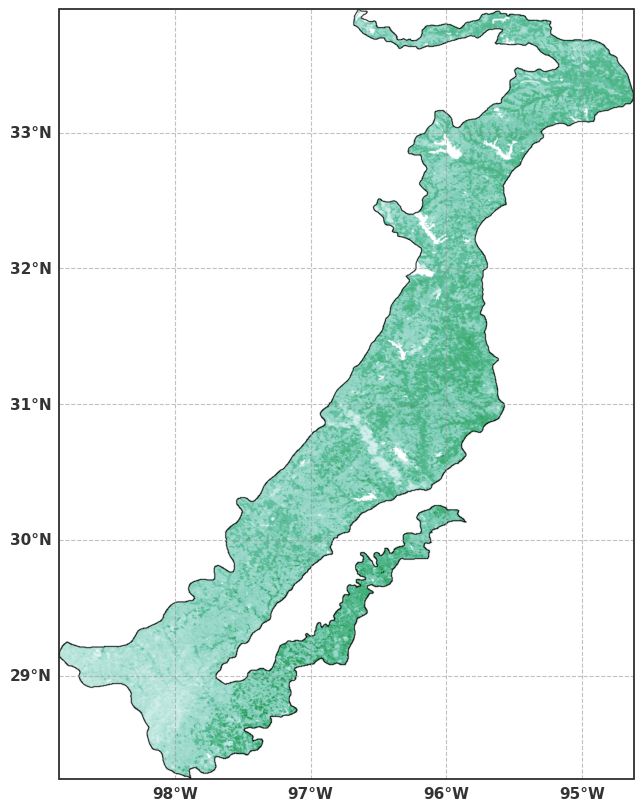

In [ ]:
# 2. Specify paths - Use the file name exported from Google Earth Engine
tiff_path = '/content/drive/MyDrive/GPP.tif'
output_png = '/content/drive/MyDrive/GPP_Final.png'

# 3. Read the geospatial dataset
with rasterio.open(tiff_path) as src:
    # plotting_extent automatically extracts the Lat/Lon bounding box bounds from metadata
    img_extent = plotting_extent(src)
    img_data = src.read()  # Reads pre-rendered RGB channels (Bands, Height, Width)

# 4. Reorder array layout from GIS structure to standard image format (Height, Width, Bands)
# and normalize color value ranges from 0-255 down to 0.0-1.0 for matplotlib compatibility
rgb_image = img_data.transpose(1, 2, 0) / 255.0

# =========================================================================
# 5. GENERATE CARTOGRAPHIC PRESENTATION FRAME
# =========================================================================
fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.PlateCarree()})

# Draw map matching its explicit spatial geographic bounds
# Note: 'origin=upper' ensures the map layout is not flipped upside-down
ax.imshow(rgb_image, extent=img_extent, transform=ccrs.PlateCarree(), origin='upper')

# =========================================================================
# 6. AUTOMATE LATITUDE & LONGITUDE LABEL GRIDLINES
# =========================================================================
gl = ax.gridlines(draw_labels=True, linestyle='--', color='#999999', alpha=0.6, linewidth=0.8)

# Clean style adjustments to match a professional manuscript layout
gl.top_labels = False    # Disable top coordinates
gl.right_labels = False  # Disable right coordinates
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

# Font specifications for readability
gl.xlabel_style = {'size': 11, 'weight': 'bold', 'color': '#333333'}
gl.ylabel_style = {'size': 11, 'weight': 'bold', 'color': '#333333'}

# =========================================================================
# 7. SAVE HIGH-RESOLUTION COMPACT PNG
# =========================================================================
# bbox_inches='tight' strips all dead margins so it drops cleanly into PowerPoint
plt.savefig(output_png, dpi=300, bbox_inches='tight', pad_inches=0.1)
print(f"🎉 Success! High-resolution map with gridlines saved to Drive:\n{output_png}")

plt.show()

🎉 Success! High-resolution map with gridlines saved to Drive:
/content/drive/MyDrive/WUE_Final.png


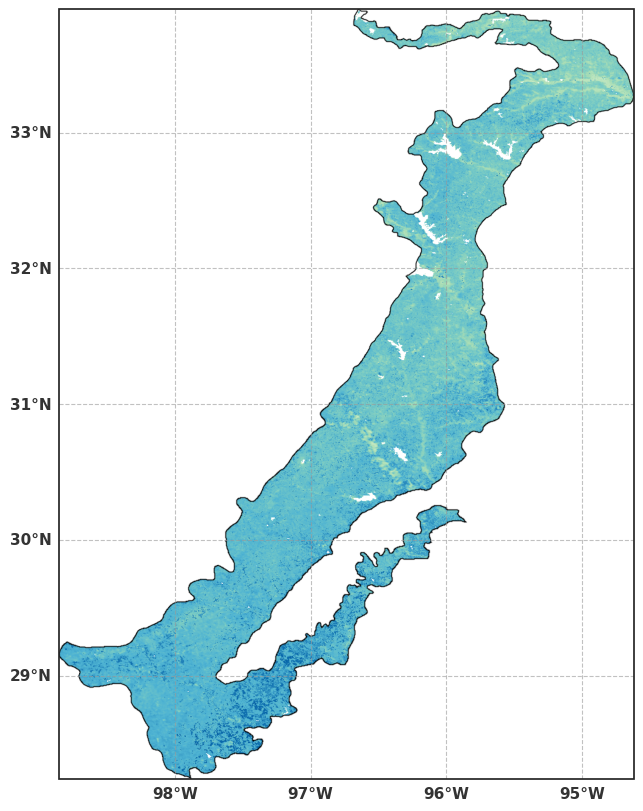

In [ ]:
# 2. Specify paths - Use the file name exported from Google Earth Engine
tiff_path = '/content/drive/MyDrive/WUE.tif'
output_png = '/content/drive/MyDrive/WUE_Final.png'

# 3. Read the geospatial dataset
with rasterio.open(tiff_path) as src:
    # plotting_extent automatically extracts the Lat/Lon bounding box bounds from metadata
    img_extent = plotting_extent(src)
    img_data = src.read()  # Reads pre-rendered RGB channels (Bands, Height, Width)

# 4. Reorder array layout from GIS structure to standard image format (Height, Width, Bands)
# and normalize color value ranges from 0-255 down to 0.0-1.0 for matplotlib compatibility
rgb_image = img_data.transpose(1, 2, 0) / 255.0

# =========================================================================
# 5. GENERATE CARTOGRAPHIC PRESENTATION FRAME
# =========================================================================
fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.PlateCarree()})

# Draw map matching its explicit spatial geographic bounds
# Note: 'origin=upper' ensures the map layout is not flipped upside-down
ax.imshow(rgb_image, extent=img_extent, transform=ccrs.PlateCarree(), origin='upper')

# =========================================================================
# 6. AUTOMATE LATITUDE & LONGITUDE LABEL GRIDLINES
# =========================================================================
gl = ax.gridlines(draw_labels=True, linestyle='--', color='#999999', alpha=0.6, linewidth=0.8)

# Clean style adjustments to match a professional manuscript layout
gl.top_labels = False    # Disable top coordinates
gl.right_labels = False  # Disable right coordinates
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

# Font specifications for readability
gl.xlabel_style = {'size': 11, 'weight': 'bold', 'color': '#333333'}
gl.ylabel_style = {'size': 11, 'weight': 'bold', 'color': '#333333'}

# =========================================================================
# 7. SAVE HIGH-RESOLUTION COMPACT PNG
# =========================================================================
# bbox_inches='tight' strips all dead margins so it drops cleanly into PowerPoint
plt.savefig(output_png, dpi=300, bbox_inches='tight', pad_inches=0.1)
print(f"🎉 Success! High-resolution map with gridlines saved to Drive:\n{output_png}")

plt.show()

## Figure 3 — spatial trends
Dependency: original cell 7 computes `spatial_trend_results.npz`; cell 10 loads it and creates the five coordinate-labelled panels that match the manuscript. Cells 8–9 are superseded plot layouts. The five-panel manuscript assembly is absent. Original cell 10 displays panels; its PNG export lines remain commented out.


In [ ]:
import numpy as np
import rasterio
from scipy import stats

# Configuration matching your Drive structure
SAVE_PATH = "./spatial_trend_results.npz" # Saves locally inside your temporary Colab workspace
START_YEAR = 2000
END_YEAR = 2024

variables = ['PET', 'AET', 'ESR', 'GPP', 'WUE']
BAND_MAPPING = {'PET': 1, 'AET': 2, 'ESR': 3, 'GPP': 4, 'WUE': 5}

years = np.arange(START_YEAR, END_YEAR + 1)
n_years = len(years)

# Pre-calculate time components
x_mean = np.mean(years)
x_dev = years - x_mean
x_var_sum = np.sum(x_dev**2)

meta_info = None
var_stacks = {var: [] for var in variables}

print("🚀 Step 1: Reading Multi-Band GeoTIFFs directly from Google Drive...")

for yr in years:
    file_path = os.path.join(DATA_DIR, f"Annual_Metrics_{yr}.tif")

    with rasterio.open(file_path) as src:
        if meta_info is None:
            meta_info = {
                'height': src.height,
                'width': src.width,
                'transform': src.transform,
                'crs': src.crs,
                'nodata': src.nodata
            }

        for var in variables:
            band_idx = BAND_MAPPING[var]
            var_stacks[var].append(src.read(band_idx))

output_slopes = {}
output_pvalues = {}

print("⚙️ Step 2: Running high-speed pixel-wise regressions...")
for var in variables:
    print(f" -> Calculating trends for {var}...")
    stack = np.stack(var_stacks[var], axis=0)
    valid_mask = (stack[0] != meta_info['nodata']) & (~np.isnan(stack[0]))

    y_flat = stack[:, valid_mask]
    y_mean = np.mean(y_flat, axis=0)

    slopes_flat = np.sum((y_flat - y_mean) * x_dev[:, None], axis=0) / x_var_sum
    intercepts_flat = y_mean - slopes_flat * x_mean

    y_pred = slopes_flat[None, :] * years[:, None] + intercepts_flat[None, :]
    rss = np.sum((y_flat - y_pred)**2, axis=0)
    df = n_years - 2

    se_slope = np.sqrt(rss / df) / np.sqrt(x_var_sum)
    t_stat = np.divide(slopes_flat, se_slope, out=np.zeros_like(slopes_flat), where=se_slope != 0)
    p_values_flat = 2 * (1 - stats.t.cdf(np.abs(t_stat), df=df))

    slope_map = np.full((meta_info['height'], meta_info['width']), np.nan)
    p_map = np.full((meta_info['height'], meta_info['width']), np.nan)

    slope_map[valid_mask] = slopes_flat
    p_map[valid_mask] = p_values_flat

    output_slopes[var] = slope_map
    output_pvalues[var] = p_map

# Save intermediate matrix result locally in Colab
np.savez_compressed(
    SAVE_PATH,
    slopes=output_slopes,
    pvalues=output_pvalues,
    nodata=meta_info['nodata']
)
print(f"✅ SUCCESS: Trend calculation file saved to: {SAVE_PATH}")

🚀 Step 1: Reading Multi-Band GeoTIFFs directly from Google Drive...
⚙️ Step 2: Running high-speed pixel-wise regressions...
 -> Calculating trends for PET...
 -> Calculating trends for AET...
 -> Calculating trends for ESR...
 -> Calculating trends for GPP...
 -> Calculating trends for WUE...
✅ SUCCESS: Trend calculation file saved to: ./spatial_trend_results.npz


/tmp/ipykernel_4780/2862190235.py:6: DeprecationWarning: The LONGITUDE_FORMATTER module-level attribute was deprecated in Cartopy 0.26. Use LongitudeFormatter instead.
  from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
/tmp/ipykernel_4780/2862190235.py:6: DeprecationWarning: The LATITUDE_FORMATTER module-level attribute was deprecated in Cartopy 0.26. Use LatitudeFormatter instead.
  from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER


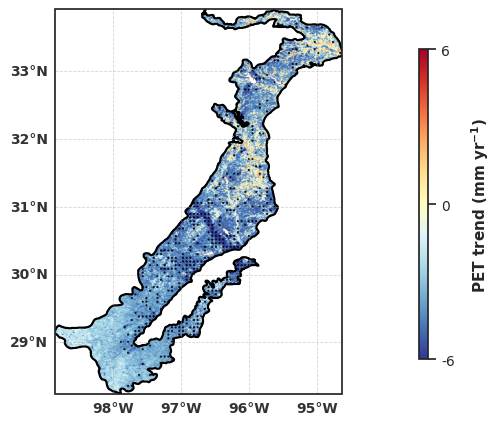

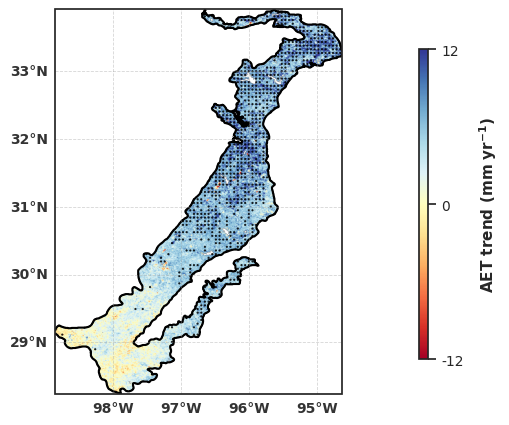

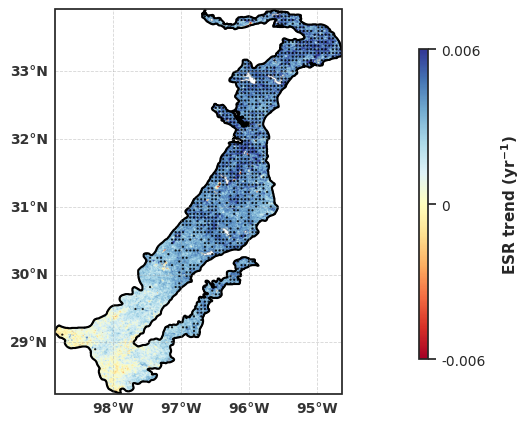

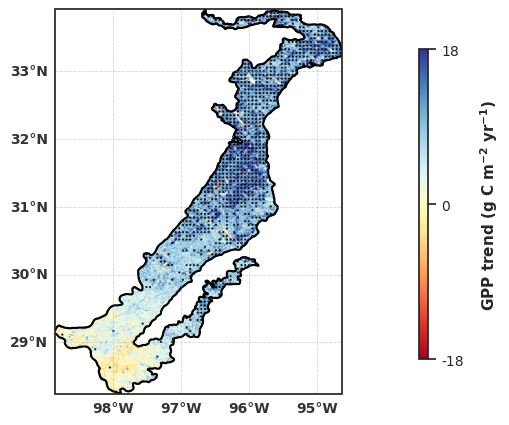

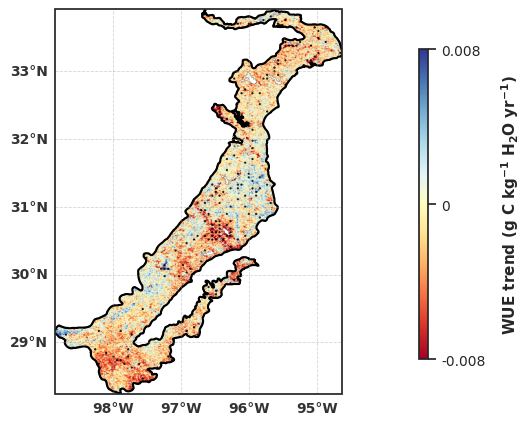

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
from scipy.ndimage import binary_fill_holes

# --- 1. Configuration Settings ---
DATA_PATH = "./spatial_trend_results.npz"
OUTPUT_DIR = "/content/drive/MyDrive/GEE_Exports/single_maps/"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# =========================================================================
# FIXED: ORIGINAL FIXED GEOGRAPHIC BOUNDS OF THE POS MATRIX
# =========================================================================
# Format: [left_lon, right_lon, bottom_lat, top_lat]
# This prevents Cartopy from flattening or stretching your native array pixels.
IMG_EXTENT = [-98.8551, -94.6195, 28.2385, 33.9114]

P_THRESHOLD = 0.05
STIPPLE_THINNING = 12
DOT_SIZE = 10

# --- 2. Load Pre-Calculated Matrices ---
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Missing trend results file. Please run Stage 1 first to save data to {DATA_PATH}")

data = np.load(DATA_PATH, allow_pickle=True)
slopes = data['slopes'].item()
pvalues = data['pvalues'].item()

variables = ['PET', 'AET', 'ESR', 'GPP', 'WUE']

LEGEND_LABELS = {
    'PET': r'PET trend ($\mathregular{mm\ yr^{-1}}$)',
    'AET': r'AET trend ($\mathregular{mm\ yr^{-1}}$)',
    'ESR': r'ESR trend ($\mathregular{yr^{-1}}$)',
    'GPP': r'GPP trend ($\mathregular{g\ C\ m^{-2}\ yr^{-1}}$)',
    'WUE': r'WUE trend ($\mathregular{g\ C\ kg^{-1}\ H_2O\ yr^{-1}}$)'
}

try:
    nodata_val = data['nodata'].item() if hasattr(data['nodata'], 'item') else data['nodata']
except Exception:
    nodata_val = None

# --- 3. Loop Through Each Variable and Save Separate Maps ---
for var in variables:
    sns.set_theme(style="white")

    # Natural aspect ratio layout for a single POS map frame
    fig = plt.figure(figsize=(6, 5))
    ax = plt.axes(projection=ccrs.PlateCarree())

    slope_map = slopes[var]
    p_map = pvalues[var]

    if var == 'PET':
        cmap = 'RdYlBu_r'
    else:
        cmap = 'RdYlBu'

    v_limit = np.nanpercentile(np.abs(slope_map), 97)

    # Render base layer using the corrected geographic extent
    im = ax.imshow(slope_map, cmap=cmap, vmin=-v_limit, vmax=v_limit,
                   extent=IMG_EXTENT, transform=ccrs.PlateCarree(), origin='upper')

    # --- Outer Perimeter Solid Vector Boundary ---
    if nodata_val is None or (isinstance(nodata_val, float) and np.isnan(nodata_val)):
        footprint = ~np.isnan(slope_map)
    else:
        footprint = (~np.isnan(slope_map)) & (slope_map != nodata_val)

    if np.any(footprint):
        clean_outer_boundary = binary_fill_holes(footprint)
        ax.contour(clean_outer_boundary.astype(float), levels=[0.5], colors='black', linewidths=1.5,
                   extent=IMG_EXTENT, transform=ccrs.PlateCarree(), origin='upper')

    # --- Pure Binary Significance Stippling (p < 0.05) ---
    sig_mask = p_map < P_THRESHOLD
    grid_mask = np.zeros_like(sig_mask, dtype=bool)
    grid_mask[::STIPPLE_THINNING, ::STIPPLE_THINNING] = True

    y_indices, x_indices = np.where(sig_mask & grid_mask)

    h, w = slope_map.shape
    x_dots = IMG_EXTENT[0] + (x_indices / w) * (IMG_EXTENT[1] - IMG_EXTENT[0])
    y_dots = IMG_EXTENT[3] - (y_indices / h) * (IMG_EXTENT[3] - IMG_EXTENT[2])

    ax.scatter(x_dots, y_dots, color='black', s=DOT_SIZE, marker='.', alpha=0.85, edgecolors='none',
               transform=ccrs.PlateCarree())

    # --- AUTOMATED COORDINATE LABELS WITH NO DISTORTION ---
    gl = ax.gridlines(draw_labels=True, linestyle='--', color='#999999', alpha=0.4, linewidth=0.6)
    gl.top_labels = False
    gl.right_labels = False
    gl.left_labels = True
    gl.bottom_labels = True

    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'weight': 'bold', 'color': '#333333'}
    gl.ylabel_style = {'size': 10, 'weight': 'bold', 'color': '#333333'}

    # =========================================================================
    # REVISED: FIXED COLORBAR POSITIONING (LEARNED FROM YOUR REFERENCE CODE)
    # =========================================================================
    # Explicitly maps an isolated axis frame for the colorbar on the right side
    cbar_ax = fig.add_axes([0.88, 0.18, 0.015, 0.62])

    three_ticks = [-v_limit, 0.0, v_limit]
    cbar = fig.colorbar(im, cax=cbar_ax, orientation='vertical', ticks=three_ticks, extend='neither')
    cbar.ax.tick_params(labelsize=10)

    # Clean label formatting per variable
    if var == 'ESR':
        cbar.ax.set_yticklabels(["-0.006", "0", "0.006"], fontsize=10)
    elif var == 'WUE':
        cbar.ax.set_yticklabels(["-0.008", "0", "0.008"], fontsize=10)
    elif var == 'PET':
        cbar.ax.set_yticklabels(["-6", "0", "6"], fontsize=10)
    elif var == 'AET':
        cbar.ax.set_yticklabels(["-12", "0", "12"], fontsize=10)
    elif var == 'GPP':
        cbar.ax.set_yticklabels(["-18", "0", "18"], fontsize=10)
    else:
        cbar.ax.set_yticklabels([f"{-v_limit:.2f}", "0.00", f"{v_limit:.2f}"], fontsize=10)

    cbar.set_label(LEGEND_LABELS[var], fontsize=11, fontweight='bold', labelpad=10)

    # Map title matching formatting
    # ax.set_title(f"POS - {var} Trend Analysis", fontsize=13, fontweight='bold', pad=12)

    # Save output map
    # SINGLE_OUTPUT_PATH = os.path.join(OUTPUT_DIR, f"{var}_trend_map.png")
    # plt.savefig(SINGLE_OUTPUT_PATH, dpi=300, bbox_inches='tight', pad_inches=0.05)
    # print(f"🎉 Successfully saved beautiful single map: {SINGLE_OUTPUT_PATH}")

    plt.show()
    plt.close()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


/tmp/ipykernel_5044/2221700087.py:6: DeprecationWarning: The LONGITUDE_FORMATTER module-level attribute was deprecated in Cartopy 0.26. Use LongitudeFormatter instead.
  from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
/tmp/ipykernel_5044/2221700087.py:6: DeprecationWarning: The LATITUDE_FORMATTER module-level attribute was deprecated in Cartopy 0.26. Use LatitudeFormatter instead.
  from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER


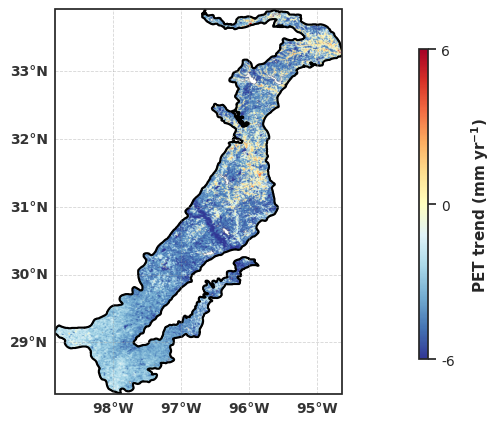

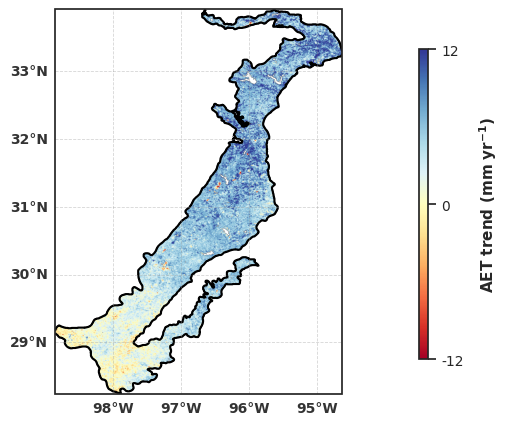

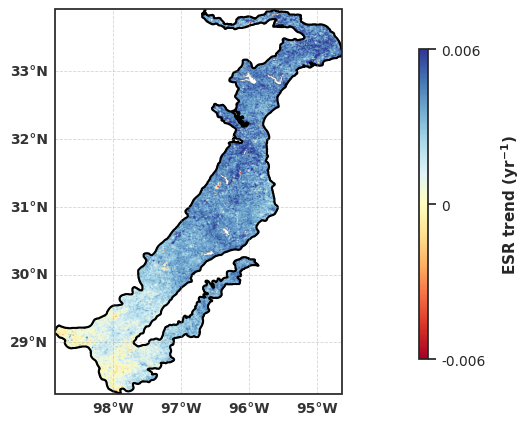

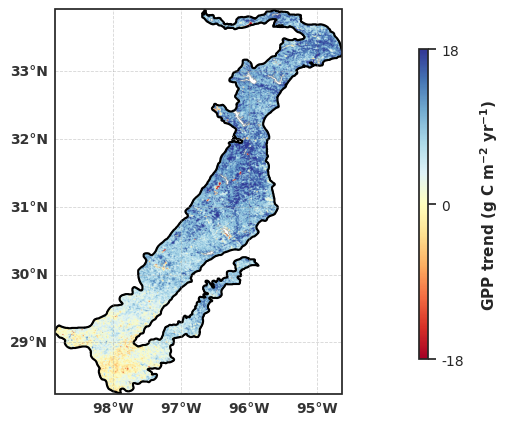

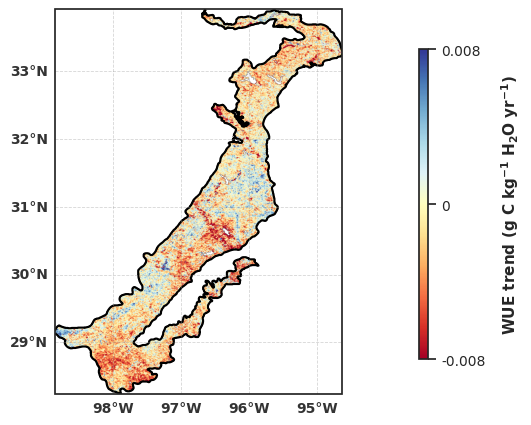

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
from scipy.ndimage import binary_fill_holes

# --- 1. Configuration Settings ---
DATA_PATH = "./spatial_trend_results.npz"
OUTPUT_DIR = "/content/drive/MyDrive/GEE_Exports/single_maps/"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# =========================================================================
# FIXED: ORIGINAL FIXED GEOGRAPHIC BOUNDS OF THE POS MATRIX
# =========================================================================
# Format: [left_lon, right_lon, bottom_lat, top_lat]
# This prevents Cartopy from flattening or stretching your native array pixels.
IMG_EXTENT = [-98.8551, -94.6195, 28.2385, 33.9114]

P_THRESHOLD = 0.05
STIPPLE_THINNING = 12
DOT_SIZE = 10

# --- 2. Load Pre-Calculated Matrices ---
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Missing trend results file. Please run Stage 1 first to save data to {DATA_PATH}")

data = np.load(DATA_PATH, allow_pickle=True)
slopes = data['slopes'].item()
pvalues = data['pvalues'].item()

variables = ['PET', 'AET', 'ESR', 'GPP', 'WUE']

LEGEND_LABELS = {
    'PET': r'PET trend ($\mathregular{mm\ yr^{-1}}$)',
    'AET': r'AET trend ($\mathregular{mm\ yr^{-1}}$)',
    'ESR': r'ESR trend ($\mathregular{yr^{-1}}$)',
    'GPP': r'GPP trend ($\mathregular{g\ C\ m^{-2}\ yr^{-1}}$)',
    'WUE': r'WUE trend ($\mathregular{g\ C\ kg^{-1}\ H_2O\ yr^{-1}}$)'
}

try:
    nodata_val = data['nodata'].item() if hasattr(data['nodata'], 'item') else data['nodata']
except Exception:
    nodata_val = None

# --- 3. Loop Through Each Variable and Save Separate Maps ---
for var in variables:
    sns.set_theme(style="white")

    # Natural aspect ratio layout for a single POS map frame
    fig = plt.figure(figsize=(6, 5))
    ax = plt.axes(projection=ccrs.PlateCarree())

    slope_map = slopes[var]
    p_map = pvalues[var]

    if var == 'PET':
        cmap = 'RdYlBu_r'
    else:
        cmap = 'RdYlBu'

    v_limit = np.nanpercentile(np.abs(slope_map), 97)

    # Render base layer using the corrected geographic extent
    im = ax.imshow(slope_map, cmap=cmap, vmin=-v_limit, vmax=v_limit,
                   extent=IMG_EXTENT, transform=ccrs.PlateCarree(), origin='upper')

    # --- Outer Perimeter Solid Vector Boundary ---
    if nodata_val is None or (isinstance(nodata_val, float) and np.isnan(nodata_val)):
        footprint = ~np.isnan(slope_map)
    else:
        footprint = (~np.isnan(slope_map)) & (slope_map != nodata_val)

    if np.any(footprint):
        clean_outer_boundary = binary_fill_holes(footprint)
        ax.contour(clean_outer_boundary.astype(float), levels=[0.5], colors='black', linewidths=1.5,
                   extent=IMG_EXTENT, transform=ccrs.PlateCarree(), origin='upper')

    # # --- Pure Binary Significance Stippling (p < 0.05) ---
    # sig_mask = p_map < P_THRESHOLD
    # grid_mask = np.zeros_like(sig_mask, dtype=bool)
    # grid_mask[::STIPPLE_THINNING, ::STIPPLE_THINNING] = True

    # y_indices, x_indices = np.where(sig_mask & grid_mask)

    # h, w = slope_map.shape
    # x_dots = IMG_EXTENT[0] + (x_indices / w) * (IMG_EXTENT[1] - IMG_EXTENT[0])
    # y_dots = IMG_EXTENT[3] - (y_indices / h) * (IMG_EXTENT[3] - IMG_EXTENT[2])

    # ax.scatter(x_dots, y_dots, color='black', s=DOT_SIZE, marker='.', alpha=0.85, edgecolors='none',
    #            transform=ccrs.PlateCarree())

    # --- AUTOMATED COORDINATE LABELS WITH NO DISTORTION ---
    gl = ax.gridlines(draw_labels=True, linestyle='--', color='#999999', alpha=0.4, linewidth=0.6)
    gl.top_labels = False
    gl.right_labels = False
    gl.left_labels = True
    gl.bottom_labels = True

    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'weight': 'bold', 'color': '#333333'}
    gl.ylabel_style = {'size': 10, 'weight': 'bold', 'color': '#333333'}

    # =========================================================================
    # REVISED: FIXED COLORBAR POSITIONING (LEARNED FROM YOUR REFERENCE CODE)
    # =========================================================================
    # Explicitly maps an isolated axis frame for the colorbar on the right side
    cbar_ax = fig.add_axes([0.88, 0.18, 0.015, 0.62])

    three_ticks = [-v_limit, 0.0, v_limit]
    cbar = fig.colorbar(im, cax=cbar_ax, orientation='vertical', ticks=three_ticks, extend='neither')
    cbar.ax.tick_params(labelsize=10)

    # Clean label formatting per variable
    if var == 'ESR':
        cbar.ax.set_yticklabels(["-0.006", "0", "0.006"], fontsize=10)
    elif var == 'WUE':
        cbar.ax.set_yticklabels(["-0.008", "0", "0.008"], fontsize=10)
    elif var == 'PET':
        cbar.ax.set_yticklabels(["-6", "0", "6"], fontsize=10)
    elif var == 'AET':
        cbar.ax.set_yticklabels(["-12", "0", "12"], fontsize=10)
    elif var == 'GPP':
        cbar.ax.set_yticklabels(["-18", "0", "18"], fontsize=10)
    else:
        cbar.ax.set_yticklabels([f"{-v_limit:.2f}", "0.00", f"{v_limit:.2f}"], fontsize=10)

    cbar.set_label(LEGEND_LABELS[var], fontsize=11, fontweight='bold', labelpad=10)

    # Map title matching formatting
    # ax.set_title(f"POS - {var} Trend Analysis", fontsize=13, fontweight='bold', pad=12)

    # Save output map
    # SINGLE_OUTPUT_PATH = os.path.join(OUTPUT_DIR, f"{var}_trend_map.png")
    # plt.savefig(SINGLE_OUTPUT_PATH, dpi=300, bbox_inches='tight', pad_inches=0.05)
    # print(f"🎉 Successfully saved beautiful single map: {SINGLE_OUTPUT_PATH}")

    plt.show()
    plt.close()

## Figure 4 — frequency, count and duration map panels
Original cells 34, 33, 35, in manuscript panel order. As for Figure 2, inputs are pre-rendered RGB GeoTIFFs. Colour scales and final composite are not generated here.


🎉 Success! High-resolution map with gridlines saved to Drive:
/content/drive/MyDrive/FD_freq_Final.png


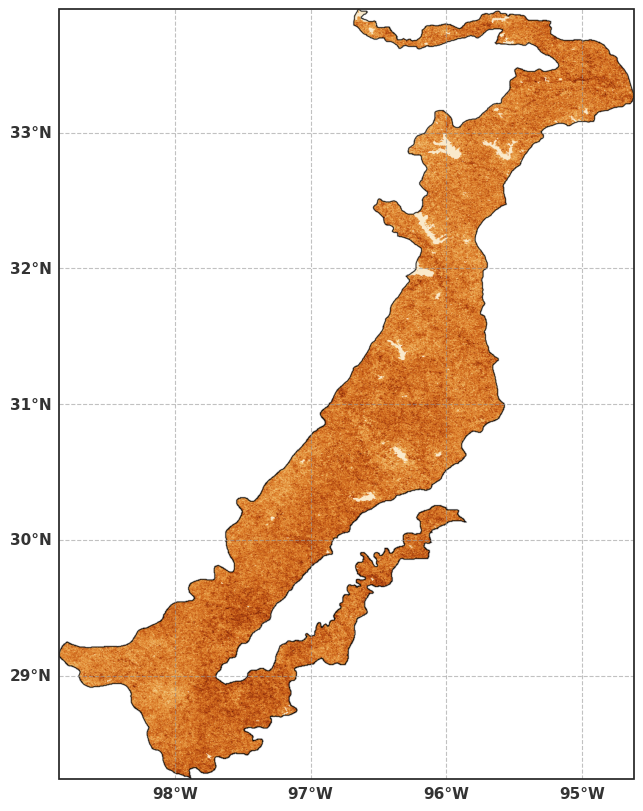

In [ ]:
sns.set_theme(style="ticks")

# 2. Specify paths - Use the file name exported from Google Earth Engine
tiff_path = '/content/drive/MyDrive/GEE_Exports/Copy of FD_freq.tif'
output_png = '/content/drive/MyDrive/FD_freq_Final.png'

# 3. Read the geospatial dataset
with rasterio.open(tiff_path) as src:
    # plotting_extent automatically extracts the Lat/Lon bounding box bounds from metadata
    img_extent = plotting_extent(src)
    img_data = src.read()  # Reads pre-rendered RGB channels (Bands, Height, Width)

# 4. Reorder array layout from GIS structure to standard image format (Height, Width, Bands)
# and normalize color value ranges from 0-255 down to 0.0-1.0 for matplotlib compatibility
rgb_image = img_data.transpose(1, 2, 0) / 255.0

# =========================================================================
# 5. GENERATE CARTOGRAPHIC PRESENTATION FRAME
# =========================================================================
fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.PlateCarree()})

# Draw map matching its explicit spatial geographic bounds
# Note: 'origin=upper' ensures the map layout is not flipped upside-down
ax.imshow(rgb_image, extent=img_extent, transform=ccrs.PlateCarree(), origin='upper')

# =========================================================================
# 6. AUTOMATE LATITUDE & LONGITUDE LABEL GRIDLINES
# =========================================================================
gl = ax.gridlines(draw_labels=True, linestyle='--', color='#999999', alpha=0.6, linewidth=0.8)

# Clean style adjustments to match a professional manuscript layout
gl.top_labels = False    # Disable top coordinates
gl.right_labels = False  # Disable right coordinates
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

# Font specifications for readability
gl.xlabel_style = {'size': 11, 'weight': 'bold', 'color': '#333333'}
gl.ylabel_style = {'size': 11, 'weight': 'bold', 'color': '#333333'}

# =========================================================================
# 7. SAVE HIGH-RESOLUTION COMPACT PNG
# =========================================================================
# bbox_inches='tight' strips all dead margins so it drops cleanly into PowerPoint
plt.savefig(output_png, dpi=300, bbox_inches='tight', pad_inches=0.1)
print(f"🎉 Success! High-resolution map with gridlines saved to Drive:\n{output_png}")

plt.show()

🎉 Success! High-resolution map with gridlines saved to Drive:
/content/drive/MyDrive/FD_count_Final.png


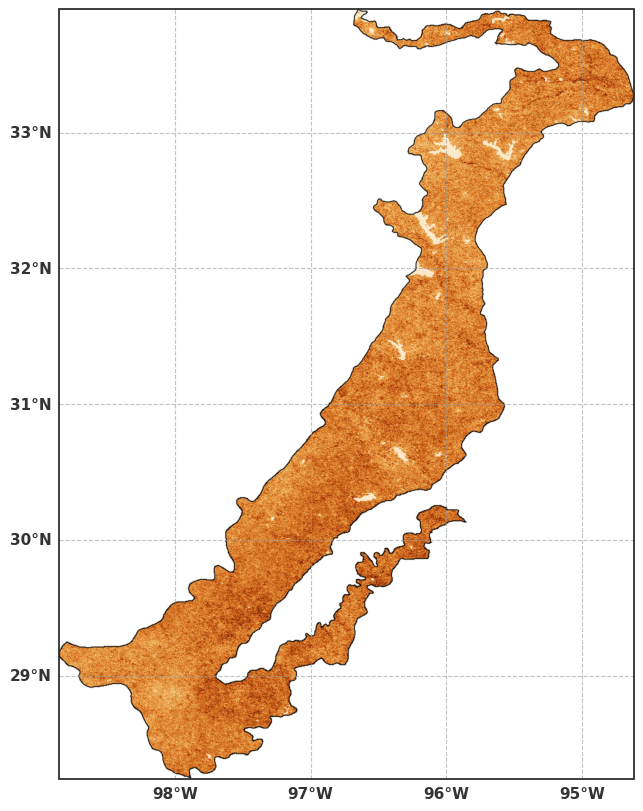

In [ ]:
# 2. Specify paths - Use the file name exported from Google Earth Engine
tiff_path = '/content/drive/MyDrive/FD_count.tif'
output_png = '/content/drive/MyDrive/FD_count_Final.png'

# 3. Read the geospatial dataset
with rasterio.open(tiff_path) as src:
    # plotting_extent automatically extracts the Lat/Lon bounding box bounds from metadata
    img_extent = plotting_extent(src)
    img_data = src.read()  # Reads pre-rendered RGB channels (Bands, Height, Width)

# 4. Reorder array layout from GIS structure to standard image format (Height, Width, Bands)
# and normalize color value ranges from 0-255 down to 0.0-1.0 for matplotlib compatibility
rgb_image = img_data.transpose(1, 2, 0) / 255.0

# =========================================================================
# 5. GENERATE CARTOGRAPHIC PRESENTATION FRAME
# =========================================================================
fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.PlateCarree()})

# Draw map matching its explicit spatial geographic bounds
# Note: 'origin=upper' ensures the map layout is not flipped upside-down
ax.imshow(rgb_image, extent=img_extent, transform=ccrs.PlateCarree(), origin='upper')

# =========================================================================
# 6. AUTOMATE LATITUDE & LONGITUDE LABEL GRIDLINES
# =========================================================================
gl = ax.gridlines(draw_labels=True, linestyle='--', color='#999999', alpha=0.6, linewidth=0.8)

# Clean style adjustments to match a professional manuscript layout
gl.top_labels = False    # Disable top coordinates
gl.right_labels = False  # Disable right coordinates
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

# Font specifications for readability
gl.xlabel_style = {'size': 11, 'weight': 'bold', 'color': '#333333'}
gl.ylabel_style = {'size': 11, 'weight': 'bold', 'color': '#333333'}

# =========================================================================
# 7. SAVE HIGH-RESOLUTION COMPACT PNG
# =========================================================================
# bbox_inches='tight' strips all dead margins so it drops cleanly into PowerPoint
plt.savefig(output_png, dpi=300, bbox_inches='tight', pad_inches=0.1)
print(f"🎉 Success! High-resolution map with gridlines saved to Drive:\n{output_png}")

plt.show()

🎉 Success! High-resolution map with gridlines saved to Drive:
/content/drive/MyDrive/FD_dur_Final.png


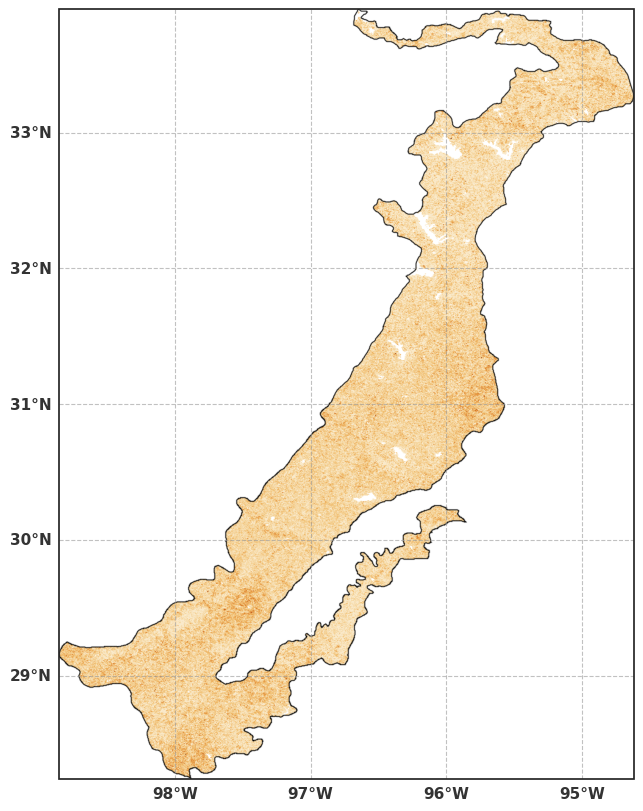

In [ ]:
# 2. Specify paths - Use the file name exported from Google Earth Engine
tiff_path = '/content/drive/MyDrive/FD_dur.tif'
output_png = '/content/drive/MyDrive/FD_dur_Final.png'

# 3. Read the geospatial dataset
with rasterio.open(tiff_path) as src:
    # plotting_extent automatically extracts the Lat/Lon bounding box bounds from metadata
    img_extent = plotting_extent(src)
    img_data = src.read()  # Reads pre-rendered RGB channels (Bands, Height, Width)

# 4. Reorder array layout from GIS structure to standard image format (Height, Width, Bands)
# and normalize color value ranges from 0-255 down to 0.0-1.0 for matplotlib compatibility
rgb_image = img_data.transpose(1, 2, 0) / 255.0

# =========================================================================
# 5. GENERATE CARTOGRAPHIC PRESENTATION FRAME
# =========================================================================
fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.PlateCarree()})

# Draw map matching its explicit spatial geographic bounds
# Note: 'origin=upper' ensures the map layout is not flipped upside-down
ax.imshow(rgb_image, extent=img_extent, transform=ccrs.PlateCarree(), origin='upper')

# =========================================================================
# 6. AUTOMATE LATITUDE & LONGITUDE LABEL GRIDLINES
# =========================================================================
gl = ax.gridlines(draw_labels=True, linestyle='--', color='#999999', alpha=0.6, linewidth=0.8)

# Clean style adjustments to match a professional manuscript layout
gl.top_labels = False    # Disable top coordinates
gl.right_labels = False  # Disable right coordinates
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

# Font specifications for readability
gl.xlabel_style = {'size': 11, 'weight': 'bold', 'color': '#333333'}
gl.ylabel_style = {'size': 11, 'weight': 'bold', 'color': '#333333'}

# =========================================================================
# 7. SAVE HIGH-RESOLUTION COMPACT PNG
# =========================================================================
# bbox_inches='tight' strips all dead margins so it drops cleanly into PowerPoint
plt.savefig(output_png, dpi=300, bbox_inches='tight', pad_inches=0.1)
print(f"🎉 Success! High-resolution map with gridlines saved to Drive:\n{output_png}")

plt.show()

## Figure 5 — seasonal event maps with inset donuts
Original cell 41 computes all four seasonal arrays and `img_extent`; cell 44 makes the manuscript version with the outer boundary. Cells 39, 42 and 43 are unnecessary earlier presentations.


In [ ]:
# Configure directory paths matching your workspace structure
GEE_EXPORTS_DIR = '/content/drive/MyDrive/GEE_Exports/'
OUTPUT_IMAGE_PATH = '/content/drive/MyDrive/GEE_Exports/seasonal_FD_EVENT_counts.png'

# Locate all annual flash drought spatial layers
tiff_files = sorted(glob.glob(os.path.join(GEE_EXPORTS_DIR, 'POS_FD_pixel_*.tif')))

if not tiff_files:
    raise FileNotFoundError(f"Could not find any 'POS_FD_pixel_*.tif' files inside {GEE_EXPORTS_DIR}")

# 2. Extract dimensions from the first file
with rasterio.open(tiff_files[0]) as src:
    img_extent = plotting_extent(src)
    height, width = src.shape

# Initialize empty grids to aggregate true EVENT counts across 2000-2024
winter_total = np.zeros((height, width))
spring_total = np.zeros((height, width))
summer_total = np.zeros((height, width))
fall_total   = np.zeros((height, width))

print(f"🔄 Processing {len(tiff_files)} annual rasters. Grouping consecutive windows into individual events...")

# 3. Process each year, grouping consecutive marked windows per pixel
for file_path in tiff_files:
    year = re.search(r'pixel_(\d{4})', os.path.basename(file_path)).group(1)

    with rasterio.open(file_path) as src:
        data = src.read()
        n_steps = (data.shape[0] - 1) // 2

        # Isolate the Flash Drought Window bands (Shape: [n_steps, height, width])
        fw_bands = data[0:n_steps*2:2, :, :]

        # Clean nodata values across the entire 3D array stack at once
        fw_bands = np.where(fw_bands == src.nodata, 0, fw_bands)
        binary_stack = (fw_bands > 0).astype(int)  # 1 where drought is active, 0 where normal

        # --- TIME SERIES PATTERN MATCHING FOR EVENT ONSETS ---
        # Shift the binary stack along the time axis (axis=0) to detect transitions
        # An event STARTS only when a window is 1 AND the previous window was 0.

        # The first window of the year (index 0) is an onset if it is a 1
        onset_stack = np.zeros_like(binary_stack)
        onset_stack[0, :, :] = binary_stack[0, :, :]

        # For windows 2 to 46, it's an onset only if it changes from 0 -> 1
        onset_stack[1:, :, :] = (binary_stack[1:, :, :] == 1) & (binary_stack[:-1, :, :] == 0)

        # 4. Route the single initiation window to the correct seasonal grid
        for step_idx in range(n_steps):
            window_num = step_idx + 1
            onset_slice = onset_stack[step_idx, :, :]

            if 1 <= window_num <= 11:
                winter_total += onset_slice
            elif 12 <= window_num <= 22:
                spring_total += onset_slice
            elif 23 <= window_num <= 34:
                summer_total += onset_slice
            elif 35 <= window_num <= 46:
                fall_total += onset_slice

print("🎨 Spatial data aggregation complete. Building cartographic subplots...")

🔄 Processing 25 annual rasters. Grouping consecutive windows into individual events...
🎨 Spatial data aggregation complete. Building cartographic subplots...


/tmp/ipykernel_4780/4238308195.py:7: DeprecationWarning: The LONGITUDE_FORMATTER module-level attribute was deprecated in Cartopy 0.26. Use LongitudeFormatter instead.
  from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
/tmp/ipykernel_4780/4238308195.py:7: DeprecationWarning: The LATITUDE_FORMATTER module-level attribute was deprecated in Cartopy 0.26. Use LatitudeFormatter instead.
  from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER


🎉 Success! Compact 1x4 event maps saved directly to:
/content/drive/MyDrive/GEE_Exports/seasonal_FD_EVENT_counts.png


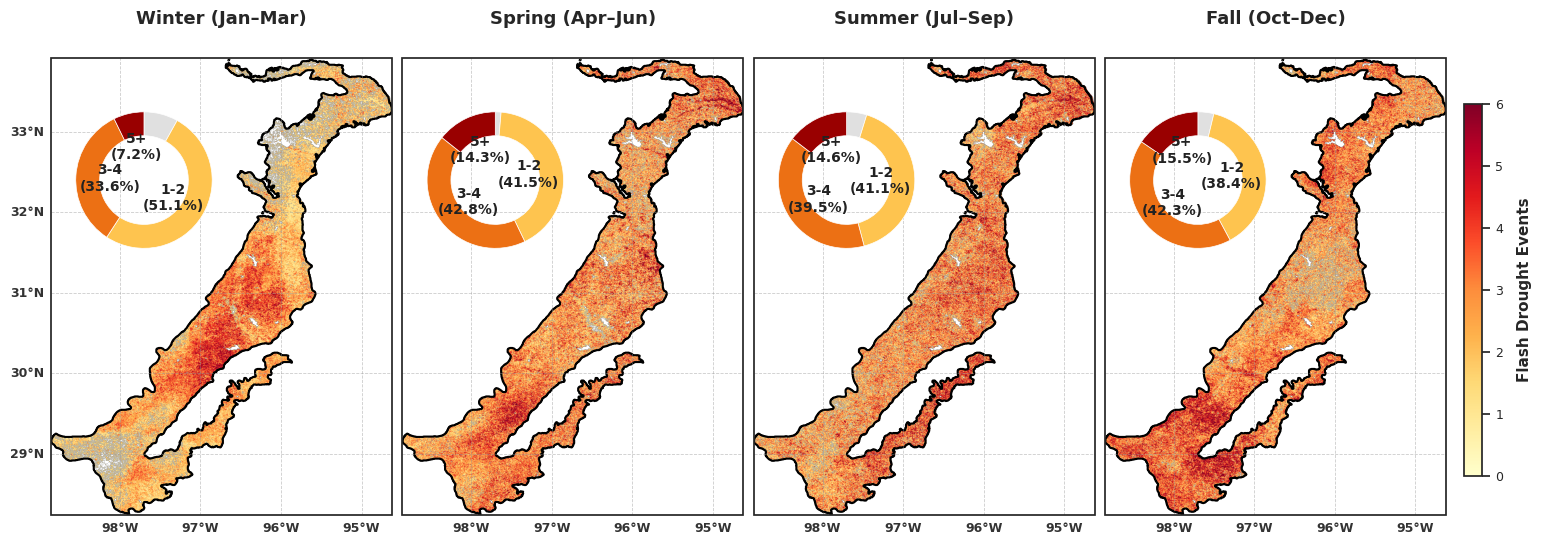

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import rasterio
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
# REVISED: Replaced simple binary_fill_holes with binary_closing and label
from scipy.ndimage import binary_closing, label

# =========================================================================
# 5. CONFIGURING COMPACT 1×4 CARTOGRAPHIC FRAME WITH SOLID OUTER BOUNDARY
# =========================================================================
seasons_data = [winter_total, spring_total, summer_total, fall_total]
seasons_labels = ['Winter (Jan–Mar)', 'Spring (Apr–Jun)', 'Summer (Jul–Sep)', 'Fall (Oct–Dec)']

fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(18, 6),
                         subplot_kw={'projection': ccrs.PlateCarree()})

# Extract the Land Cover band from your GeoTIFF to define the real POS boundaries
with rasterio.open(tiff_files[0]) as src_mask:
    lc_band = src_mask.read(src_mask.count)

# --- GENERATE A PERFECT SOLID MASK FOR THE OUTER BOUNDARY ONLY ---
raw_mask = (lc_band != src_mask.nodata) & (lc_band > 0)

# REVISED: Advanced perimeter extraction that guarantees internal lakes/rivers are ignored
if np.any(raw_mask):
    # 1. Close thin inlets, rivers, or narrow breaks linking internal water bodies to the map background
    closed_mask = binary_closing(raw_mask, structure=np.ones((3, 3)))

    # 2. Assign unique numerical labels to every isolated empty space component (where mask is False)
    labeled_bg, num_features = label(~closed_mask)

    # 3. Locate the actual frame canvas background using the 4 corners of the matrix grid
    h, w = raw_mask.shape
    corners = [labeled_bg[0, 0], labeled_bg[0, w-1], labeled_bg[h-1, 0], labeled_bg[h-1, w-1]]
    bg_candidates = [c for c in corners if c > 0]

    if bg_candidates:
        # Identify which label appears most frequently in the image frame corners
        outside_label = max(set(bg_candidates), key=bg_candidates.count)
        # Anything that is NOT the true outside background belongs to the solid study area
        solid_boundary_mask = (labeled_bg != outside_label)
    else:
        # Fallback: if corners aren't background labels, treat the largest empty block as outside
        sizes = np.bincount(labeled_bg.ravel())
        if len(sizes) > 1:
            outside_label = np.argmax(sizes[1:]) + 1
            solid_boundary_mask = (labeled_bg != outside_label)
        else:
            solid_boundary_mask = raw_mask
else:
    solid_boundary_mask = raw_mask

for i in range(4):
    ax = axes[i]
    raw_grid = seasons_data[i]
    grid_data = raw_grid.astype(float)

    # -----------------------------------------------------------------
    # A. CALCULATE LAND AREA PERCENTAGE STATISTICS WITH POS MASK
    # -----------------------------------------------------------------
    valid_pixels = raw_grid[raw_mask]
    total_valid_count = len(valid_pixels) if len(valid_pixels) > 0 else 1

    pct_0     = (np.sum(valid_pixels == 0) / total_valid_count) * 100
    pct_1_2   = (np.sum((valid_pixels >= 1) & (valid_pixels <= 2)) / total_valid_count) * 100
    pct_3_4   = (np.sum((valid_pixels >= 3) & (valid_pixels <= 4)) / total_valid_count) * 100
    pct_5plus = (np.sum(valid_pixels >= 5) / total_valid_count) * 100

    stat_percentages = [pct_0, pct_1_2, pct_3_4, pct_5plus]
    stat_labels = ['0', '1-2', '3-4', '5+']

   # Filter out categories that have 0% area so they don't crowd the pie chart text
    pie_slices = []
    pie_labels = []
    pie_colors = []
    all_colors = ['#e0e0e0', '#fec44f', '#ec7014', '#990000']

    for pct, label_str, color in zip(stat_percentages, stat_labels, all_colors):
        if pct > 0:
            pie_slices.append(pct)

            # REVISED: If the category is '0', give it an empty string label so no text appears
            if label_str == '0':
                pie_labels.append("")
            else:
                pie_labels.append(f"{label_str}\n({pct:.1f}%)" if pct > 2 else "")

            pie_colors.append(color)

    # -----------------------------------------------------------------
    # B. CRISP REGION CONTOUR OUTLINE & RENDER MAIN MAP PANEL
    # -----------------------------------------------------------------
    grid_data[grid_data == 0] = np.nan

    # Render base maps with your continuous look completely preserved
    im = ax.imshow(grid_data, extent=img_extent, transform=ccrs.PlateCarree(),
                   origin='upper', cmap='YlOrRd', vmin=0, vmax=6)

    # REVISED: Traces ONLY the outer boundary edge of the generated solid mask layer
    ax.contour(solid_boundary_mask.astype(float), levels=[0.5], colors=['black'],
               linewidths=[1.5], extent=img_extent, transform=ccrs.PlateCarree(), origin='upper')

    # Title formatting with safety padding to prevent overlaying the donut charts
    ax.set_title(seasons_labels[i], fontsize=13, fontweight='bold', pad=25)

    # -----------------------------------------------------------------
    # C. EMBED INSET DONUT/PIE CHART (UPPER-LEFT CORNER)
    # -----------------------------------------------------------------
    ax_inset = inset_axes(ax, width="50%", height="50%", loc=2, borderpad=0.5)

    wedges, texts = ax_inset.pie(
        pie_slices,
        labels=pie_labels,
        colors=pie_colors,
        startangle=90,
        counterclock=False,
        textprops=dict(fontsize=10, fontweight='bold', color='#222222'),
        wedgeprops=dict(width=0.35, edgecolor='white', linewidth=0.5),
        labeldistance=0.5  # Centers the text labels over the ring paths to prevent border clipping
    )

    for text in texts:
        text.set_horizontalalignment('center')

    # -----------------------------------------------------------------
    # D. COORDINATE LAT/LON LINES
    # -----------------------------------------------------------------
    gl = ax.gridlines(draw_labels=True, linestyle='--', color='#999999', alpha=0.5, linewidth=0.6)
    gl.top_labels = False
    gl.right_labels = False

    if i > 0:
        gl.left_labels = False

    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 9, 'weight': 'bold', 'color': '#333333'}
    gl.ylabel_style = {'size': 9, 'weight': 'bold', 'color': '#333333'}

# Universal Colorbar Scale (Flat ended)
cbar_ax = fig.add_axes([0.91, 0.18, 0.01, 0.62])
cbar = fig.colorbar(im, cax=cbar_ax, orientation='vertical', extend='neither')
cbar.set_label('Flash Drought Events', fontsize=11, fontweight='bold', labelpad=10)
cbar.ax.tick_params(labelsize=9)

# Compress horizontal gaps between columns tightly
plt.subplots_adjust(wspace=0.03)

# =========================================================================
# 6. EXPORT PNG
# =========================================================================
plt.savefig(OUTPUT_IMAGE_PATH, dpi=300, bbox_inches='tight', pad_inches=0.05)
print(f"🎉 Success! Compact 1x4 event maps saved directly to:\n{OUTPUT_IMAGE_PATH}")

## Figure 6 — monthly fractional area
Keep original cell 45 even though its saved output shows an old horizontal chart: its current source computes `mean_fractions` used by cell 46. The old horizontal plotting source is no longer present in cell 45. The palette previously came from an unrelated annual-plot section; it is now explicit here.


In [ ]:
import os
import glob
import re
import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =========================================================================
# 1. PATH CONFIGURATION & DICTIONARY SETTINGS
# =========================================================================
tiff_dir = '/content/drive/MyDrive/GEE_Exports/'
tiff_files = sorted(glob.glob(os.path.join(tiff_dir, 'POS_FD_pixel_*.tif')))

if not tiff_files:
    raise FileNotFoundError(f"No files matching 'POS_FD_pixel_*.tif' found in {tiff_dir}")

# Define standard IGBP groupings
lc_mapping = {
    1: 'Forests', 2: 'Forests', 3: 'Forests', 4: 'Forests', 5: 'Forests',
    6: 'Savanna & Shrublands', 7: 'Savanna & Shrublands',
    8: 'Savanna & Shrublands', 9: 'Savanna & Shrublands',
    10: 'Grasslands',
    12: 'Croplands', 14: 'Croplands'
}
lc_order = ['Forests', 'Savanna & Shrublands', 'Grasslands', 'Croplands']

# =========================================================================
# 2. ITERATE OVER GEOTIFFS TO AGGREGATE MONTHLY FRACTIONS
# =========================================================================
print(f"🔄 Processing {len(tiff_files)} spatial layers...")

# Matrix template tracking: [month][lc_type] -> list of yearly total fractional footprints
monthly_accumulated = {m: {lc: [] for lc in lc_order} for m in range(1, 13)}
processed_years = set()

for file_path in tiff_files:
    filename = os.path.basename(file_path)
    year_match = re.search(r'\d{4}', filename)
    if not year_match: continue
    year = int(year_match.group())
    if year in processed_years: continue
    processed_years.add(year)

    with rasterio.open(file_path) as src:
        band_names = src.descriptions

        # Pull indices for flash drought window status ('fw_X') and land cover class
        fw_bands = [i+1 for i, name in enumerate(band_names) if name and name.startswith('fw')]
        lc_band_idx = band_names.index('LC_class') + 1

        # Read maps as data matrices
        fw_data = src.read(fw_bands)    # Dynamic Shape: (N_bands, Height, Width)
        lc_data = src.read(lc_band_idx)   # Shape: (Height, Width)

        n_bands = fw_data.shape[0]  # This will dynamically evaluate to 42 based on your error

        # --- FIXED: Dynamically map only the available number of bands to calendar months ---
        window_to_month = []
        for step in range(n_bands):
            day_of_year = step * 8 + 1
            if day_of_year <= 31: m = 1
            elif day_of_year <= 59: m = 2
            elif day_of_year <= 90: m = 3
            elif day_of_year <= 120: m = 4
            elif day_of_year <= 151: m = 5
            elif day_of_year <= 181: m = 6
            elif day_of_year <= 212: m = 7
            elif day_of_year <= 243: m = 8
            elif day_of_year <= 273: m = 9
            elif day_of_year <= 304: m = 10
            elif day_of_year <= 334: m = 11
            else: m = 12
            window_to_month.append(m)

        # Base study mask (ignore no-data fields)
        study_mask = (lc_data > 0) & (lc_data != src.nodata)

        # Group the steps into their respective 12 calendar months
        for m in range(1, 13):
            # Locate all 8-day band slices that fall within month 'm'
            month_band_indices = [i for i, month_mapped in enumerate(window_to_month) if month_mapped == m]

            # Safety: If a calendar month contains no bands in your specific shortened POS window, skip it
            if not month_band_indices: continue

            # Extract boolean drought occurrences within this month's frame
            drought_in_month = np.any(fw_data[month_band_indices, :, :] == 1, axis=0)

            for lc_code, lc_name in lc_mapping.items():
                if lc_name not in lc_order: continue

                # Total ecosystem baseline pixels
                lc_total_pixels = np.sum((lc_data == lc_code) & study_mask)
                if lc_total_pixels == 0: continue

                # Pixels experiencing drought within this land cover class
                drought_pixels = np.sum((lc_data == lc_code) & study_mask & drought_in_month)

                # Convert footprint to percentage
                fraction = (drought_pixels / lc_total_pixels) * 100
                monthly_accumulated[m][lc_name].append(fraction)

# Calculate mean fractional area values across our historical timeline
mean_fractions = {m: {} for m in range(1, 13)}
for m in range(1, 13):
    for lc in lc_order:
        data_list = monthly_accumulated[m][lc]
        mean_fractions[m][lc] = np.mean(data_list) if data_list else 0.0

🔄 Processing 25 spatial layers...


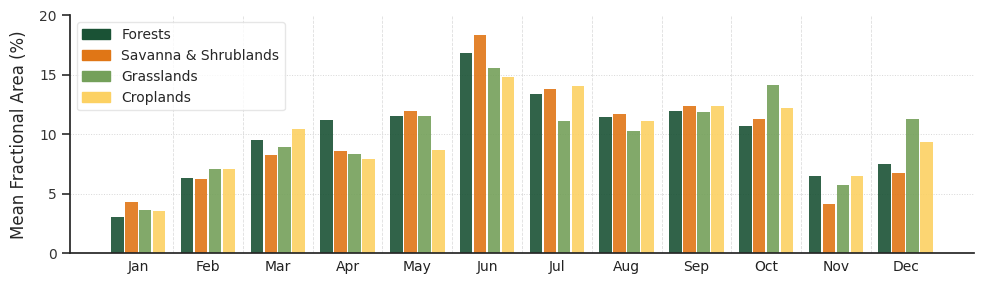

In [ ]:
palette = {'Forests': '#1a5235', 'Savanna & Shrublands': '#e07616',
           'Grasslands': '#74a05a', 'Croplands': '#fcd163'}

# =========================================================================
# 3. CONFIGURE STRUCTURAL VERTICAL PLOT LAYOUT (X-Axis: Jan to Dec)
# =========================================================================
month_strings = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
                 7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}

sns.set_theme(style="ticks")
fig, ax = plt.subplots(figsize=(10, 3))  # Widescreen proportions work best for Jan-Dec timelines

# Multi-tiered horizontal layout variables
bar_width = 0.18        # Width of individual land cover columns
lc_spacing = 0.20       # Center step size between land cover bars inside a single month cluster
month_spacing = 1.0     # Step size to completely clear one month block to the next on the X-axis

x_ticks_positions = []
x_ticks_labels = []

current_x_base = 0.0

for m_num in range(1, 13):
    month_label = month_strings[m_num]

    # Calculate center point of this month cluster for perfect X-axis label alignment
    month_center_x = current_x_base + ((len(lc_order) - 1) * lc_spacing) / 2.0
    x_ticks_positions.append(month_center_x)
    x_ticks_labels.append(month_label)

    for lc_idx, lc in enumerate(lc_order):
        # Position columns side-by-side from left to right within the month cluster
        x_pos = current_x_base + (lc_idx * lc_spacing)
        fraction_value = mean_fractions[m_num][lc]

        current_color = palette.get(lc, '#808080')

        # Plot vertical bars (bar instead of barh)
        ax.bar(x_pos, fraction_value, width=bar_width,
               color=current_color, edgecolor='none', alpha=0.9)

    # Draw a subtle vertical separator line between chronological month blocks
    if m_num < 12:
        sep_x = current_x_base + (len(lc_order) * lc_spacing) - (lc_spacing / 2) + (month_spacing - len(lc_order)*lc_spacing)/2
        ax.axvline(sep_x, color='#d0d0d0', linestyle='--', linewidth=0.6, alpha=0.7)

    current_x_base += month_spacing

# =========================================================================
# 4. AESTHETIC GRAPH REFINEMENTS
# =========================================================================
# Apply main chronological month identifiers to the primary X-Axis
ax.set_xticks(x_ticks_positions)
ax.set_xticklabels(x_ticks_labels, fontsize=10, color='#222222')
ax.tick_params(axis='x', which='major', pad=5, length=0)

# Configure the vertical Y-axis (Fractional Area Percentage)
ax.set_ylabel('Mean Fractional Area (%)', fontsize=12, labelpad=8)
ax.yaxis.set_ticks_position('left')
ax.tick_params(axis='y', labelsize=10, colors='#333333')

# Dynamically buffer Y axis height based on maximum computed value
# max_val = max(mean_fractions[m][lc] for m in range(1, 13) for lc in lc_order)
# ax.set_ylim(0, max(20, int(max_val + 5)))
ax.set_ylim(0, 20)
ax.set_yticks([0, 5, 10, 15, 20])

# Background grid lines along the Y-axis for easy valuation parsing
ax.grid(axis='y', linestyle=':', color='#b0b0b0', alpha=0.5, linewidth=0.7)
sns.despine(ax=ax, left=False, top=True, right=True, bottom=False)

# Add custom ecosystem legend box
legend_handles = [plt.Rectangle((0,0), 1, 1, color=palette[lc]) for lc in lc_order]
ax.legend(legend_handles, lc_order, loc='upper left', frameon=True,
          facecolor='white', edgecolor='#e0e0e0', fontsize=10, title="")

# plt.title('Monthly Distribution of Flash Drought Mean Fractional Area by Ecosystem Class (2000–2024)',
#           fontsize=13, fontweight='bold', pad=20, color='#111111')

plt.tight_layout()
plt.show()

In [ ]:
import os
import glob
import re
import rasterio
import numpy as np
import pandas as pd

# ============================================================
# ANNUAL LAND-COVER FD METRICS FOR STATISTICAL COMPARISON
# Years are the replicate/block unit
# ============================================================

tiff_dir = '/content/drive/MyDrive/GEE_Exports/'
files = sorted(glob.glob(os.path.join(tiff_dir, 'POS_FD_pixel_*.tif')))

if not files:
    raise FileNotFoundError("No POS_FD_pixel_*.tif files found.")

# Same grouping used in manuscript
lc_mapping = {
    1: 'Forests', 2: 'Forests', 3: 'Forests',
    4: 'Forests', 5: 'Forests',

    6: 'Savanna & Shrublands',
    7: 'Savanna & Shrublands',
    8: 'Savanna & Shrublands',
    9: 'Savanna & Shrublands',

    10: 'Grasslands',

    12: 'Croplands',
    14: 'Croplands'
}

lc_order = [
    'Forests',
    'Savanna & Shrublands',
    'Grasslands',
    'Croplands'
]

records = []

for file_path in files:

    filename = os.path.basename(file_path)

    match = re.search(r'(\d{4})', filename)
    if not match:
        continue

    year = int(match.group(1))

    with rasterio.open(file_path) as src:

        band_names = list(src.descriptions)

        # FD-window bands
        fw_bands = [
            i + 1 for i, name in enumerate(band_names)
            if name and name.startswith('fw')
        ]

        if 'LC_class' not in band_names:
            print(f"Skipping {filename}: LC_class missing")
            continue

        lc_idx = band_names.index('LC_class') + 1

        fw = src.read(fw_bands)
        lc = src.read(lc_idx)

        # Convert nodata in FD bands to zero
        if src.nodata is not None:
            fw = np.where(fw == src.nodata, 0, fw)

        fw = (fw > 0).astype(np.uint8)

        # ----------------------------------------------------
        # Event count for every pixel
        # contiguous FD windows = one event
        # ----------------------------------------------------
        padded = np.concatenate(
            [
                np.zeros((1, fw.shape[1], fw.shape[2]), dtype=np.uint8),
                fw,
                np.zeros((1, fw.shape[1], fw.shape[2]), dtype=np.uint8)
            ],
            axis=0
        )

        diff = np.diff(padded, axis=0)

        event_count = np.sum(diff == 1, axis=0)

        total_windows = np.sum(fw, axis=0)

        # Any FD in this year?
        any_fd = event_count > 0

        # Mean event duration for pixels with FD
        # Same event-duration formulation used in your workflow:
        # (mean number of overlapping windows + 3) * 8 days
        duration = np.full(event_count.shape, np.nan, dtype=float)

        duration[any_fd] = (
            (
                total_windows[any_fd] /
                event_count[any_fd]
            ) + 3
        ) * 8.0

        # ----------------------------------------------------
        # Aggregate by land-cover group
        # ----------------------------------------------------
        for lc_group in lc_order:

            raw_classes = [
                k for k, v in lc_mapping.items()
                if v == lc_group
            ]

            class_mask = np.isin(lc, raw_classes)

            n_pixels = np.sum(class_mask)

            if n_pixels == 0:
                continue

            # Annual frequency:
            # % of pixels in this class experiencing >=1 FD
            frequency_pct = (
                np.mean(any_fd[class_mask]) * 100
            )

            # Annual mean event count per pixel
            # Includes zeros for pixels with no FD
            count_mean = np.mean(
                event_count[class_mask]
            )

            # Annual mean duration only where FD occurred
            duration_mean = np.nanmean(
                duration[class_mask]
            )

            records.append({
                'Year': year,
                'LC_Group': lc_group,
                'Frequency_pct': frequency_pct,
                'Count_per_pixel': count_mean,
                'Duration_days': duration_mean,
                'N_pixels': n_pixels
            })


annual_fd_lc = pd.DataFrame(records)

annual_fd_lc = annual_fd_lc.sort_values(
    ['Year', 'LC_Group']
).reset_index(drop=True)

print(annual_fd_lc.head(12))
print("\nYears:",
      annual_fd_lc['Year'].min(),
      "-",
      annual_fd_lc['Year'].max())

annual_fd_lc.to_csv(
    '/content/drive/MyDrive/GEE_Exports/'
    'annual_FD_metrics_by_landcover.csv',
    index=False
)

    Year              LC_Group  Frequency_pct  Count_per_pixel  Duration_days  \
0   2000             Croplands          100.0         1.318654      35.162430   
1   2000               Forests          100.0         1.173842      35.064958   
2   2000            Grasslands          100.0         1.311055      35.759847   
3   2000  Savanna & Shrublands          100.0         1.223925      36.253284   
4   2001             Croplands          100.0         1.106488      32.602278   
5   2001               Forests          100.0         1.097581      32.420350   
6   2001            Grasslands          100.0         1.081212      32.813670   
7   2001  Savanna & Shrublands          100.0         1.094659      32.622746   
8   2002             Croplands          100.0         1.108886      32.835211   
9   2002               Forests          100.0         1.100719      32.415667   
10  2002            Grasslands          100.0         1.093989      32.675624   
11  2002  Savanna & Shrublan

In [ ]:
summary = (
    annual_fd_lc
    .groupby('LC_Group')
    .agg(
        Frequency_mean=('Frequency_pct', 'mean'),
        Frequency_SD=('Frequency_pct', 'std'),

        Count_annual_mean=('Count_per_pixel', 'mean'),
        Count_annual_SD=('Count_per_pixel', 'std'),

        Duration_mean=('Duration_days', 'mean'),
        Duration_SD=('Duration_days', 'std')
    )
    .reindex(lc_order)
)

# Convert annual mean count to approximate 25-year total count
summary['Count_25yr_equivalent'] = (
    summary['Count_annual_mean'] * 25
)

print(summary.round(3))

                      Frequency_mean  Frequency_SD  Count_annual_mean  \
LC_Group                                                                
Forests                        100.0           0.0              1.190   
Savanna & Shrublands           100.0           0.0              1.162   
Grasslands                     100.0           0.0              1.151   
Croplands                      100.0           0.0              1.149   

                      Count_annual_SD  Duration_mean  Duration_SD  \
LC_Group                                                            
Forests                         0.100         32.840        0.842   
Savanna & Shrublands            0.117         32.786        0.811   
Grasslands                      0.137         33.019        0.861   
Croplands                       0.123         33.075        0.746   

                      Count_25yr_equivalent  
LC_Group                                     
Forests                              29.741  
Savanna 

In [ ]:
# ============================================================
# TABLE 2: INTERANNUAL VARIABILITY AND LAND-COVER COMPARISONS
# ============================================================

import os
import numpy as np
import pandas as pd
import rasterio
from scipy.stats import friedmanchisquare, wilcoxon
from itertools import combinations
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

DATA_DIR = "/content/drive/MyDrive/GEE_Exports"

START_YEAR = 2000
END_YEAR = 2024
years = range(START_YEAR, END_YEAR + 1)

variables = ['PET', 'AET', 'ESR', 'GPP', 'WUE']

BAND_MAPPING = {
    'PET': 1,
    'AET': 2,
    'ESR': 3,
    'GPP': 4,
    'WUE': 5
}

# Same IGBP grouping used in manuscript
LC_MAPPING = {
    1: 'Forests',
    2: 'Forests',
    3: 'Forests',
    4: 'Forests',
    5: 'Forests',

    6: 'Savanna & Shrublands',
    7: 'Savanna & Shrublands',
    8: 'Savanna & Shrublands',
    9: 'Savanna & Shrublands',

    10: 'Grasslands',

    12: 'Croplands',
    14: 'Croplands'
}

LC_ORDER = [
    'Forests',
    'Savanna & Shrublands',
    'Grasslands',
    'Croplands'
]

# ------------------------------------------------------------
# 2. Read the 2020 static land-cover classification
# ------------------------------------------------------------
# LC_class is stored in POS_FD_pixel_2020.tif

LC_FILE = os.path.join(DATA_DIR, "POS_FD_pixel_2020.tif")

with rasterio.open(LC_FILE) as src:
    band_names = list(src.descriptions)

    print("Land-cover file bands:")
    print(band_names)

    if 'LC_class' not in band_names:
        raise ValueError("LC_class band was not found.")

    lc_band = band_names.index('LC_class') + 1
    lc = src.read(lc_band)

    lc_transform = src.transform
    lc_crs = src.crs

print("2020 land-cover raster loaded.")
print("Shape:", lc.shape)

# ------------------------------------------------------------
# 3. Calculate one mean value per year × land-cover × variable
# ------------------------------------------------------------

records = []

for year in years:

    metric_file = os.path.join(
        DATA_DIR,
        f"Annual_Metrics_{year}.tif"
    )

    if not os.path.exists(metric_file):
        print(f"Missing: {metric_file}")
        continue

    print(f"Processing {year}...")

    with rasterio.open(metric_file) as src:

        # Safety checks
        if src.height != lc.shape[0] or src.width != lc.shape[1]:
            raise ValueError(
                f"Raster dimensions do not match for {year}: "
                f"{src.height} × {src.width} vs LC {lc.shape}"
            )

        if src.crs != lc_crs:
            print(f"WARNING: CRS differs in {year}")

        nodata = src.nodata

        for var in variables:

            arr = src.read(
                BAND_MAPPING[var]
            ).astype(float)

            # Valid metric pixels
            valid_metric = np.isfinite(arr)

            if nodata is not None:
                valid_metric &= (arr != nodata)

            # Calculate spatial mean within each land-cover group
            for lc_group in LC_ORDER:

                lc_codes = [
                    code
                    for code, name in LC_MAPPING.items()
                    if name == lc_group
                ]

                mask = (
                    np.isin(lc, lc_codes)
                    & valid_metric
                )

                values = arr[mask]

                if len(values) == 0:
                    mean_value = np.nan
                else:
                    mean_value = np.mean(values)

                records.append({
                    'Year': year,
                    'Variable': var,
                    'LC_Group': lc_group,
                    'Mean': mean_value,
                    'N_pixels': len(values)
                })


annual_table2 = pd.DataFrame(records)

print("\nAnnual dataset:")
print(annual_table2.head(20))

# Save for future use
ANNUAL_OUTPUT = os.path.join(
    DATA_DIR,
    "Table2_annual_landcover_metrics.csv"
)

annual_table2.to_csv(
    ANNUAL_OUTPUT,
    index=False
)

print("\nSaved:")
print(ANNUAL_OUTPUT)

Land-cover file bands:
['fw00', 'fi00', 'fw01', 'fi01', 'fw02', 'fi02', 'fw03', 'fi03', 'fw04', 'fi04', 'fw05', 'fi05', 'fw06', 'fi06', 'fw07', 'fi07', 'fw08', 'fi08', 'fw09', 'fi09', 'fw10', 'fi10', 'fw11', 'fi11', 'fw12', 'fi12', 'fw13', 'fi13', 'fw14', 'fi14', 'fw15', 'fi15', 'fw16', 'fi16', 'fw17', 'fi17', 'fw18', 'fi18', 'fw19', 'fi19', 'fw20', 'fi20', 'fw21', 'fi21', 'fw22', 'fi22', 'fw23', 'fi23', 'fw24', 'fi24', 'fw25', 'fi25', 'fw26', 'fi26', 'fw27', 'fi27', 'fw28', 'fi28', 'fw29', 'fi29', 'fw30', 'fi30', 'fw31', 'fi31', 'fw32', 'fi32', 'fw33', 'fi33', 'fw34', 'fi34', 'fw35', 'fi35', 'fw36', 'fi36', 'fw37', 'fi37', 'fw38', 'fi38', 'fw39', 'fi39', 'fw40', 'fi40', 'fw41', 'fi41', 'fw42', 'fi42', 'fw43', 'fi43', 'fw44', 'fi44', 'fw45', 'fi45', 'LC_class']
2020 land-cover raster loaded.
Shape: (1263, 943)
Processing 2000...
Processing 2001...
Processing 2002...
Processing 2003...
Processing 2004...
Processing 2005...
Processing 2006...
Processing 2007...
Processing 2008...
Process

In [ ]:
# ============================================================
# 4. CHECK WHETHER THE VALUES REPRODUCE TABLE 2
# ============================================================

summary = (
    annual_table2
    .groupby(['Variable', 'LC_Group'])['Mean']
    .agg(['mean', 'std', 'count'])
    .reset_index()
)

summary['mean_SD'] = (
    summary['mean'].round(3).astype(str)
    + " ± "
    + summary['std'].round(3).astype(str)
)

summary_table = summary.pivot(
    index='Variable',
    columns='LC_Group',
    values='mean_SD'
)

summary_table = summary_table.reindex(
    index=variables,
    columns=LC_ORDER
)

print(summary_table)

LC_Group             Forests Savanna & Shrublands         Grasslands  \
Variable                                                               
PET         1732.35 ± 43.522    1704.397 ± 56.782   1695.99 ± 78.285   
AET       1014.793 ± 132.261    836.492 ± 105.128   603.463 ± 99.851   
ESR            0.586 ± 0.079        0.492 ± 0.072       0.359 ± 0.07   
GPP       1479.553 ± 192.663   1453.807 ± 163.806  1099.574 ± 141.95   
WUE            1.471 ± 0.054        1.763 ± 0.061      1.842 ± 0.092   

LC_Group          Croplands  
Variable                     
PET       1676.366 ± 88.587  
AET        582.793 ± 88.551  
ESR           0.352 ± 0.067  
GPP       1025.35 ± 126.034  
WUE           1.777 ± 0.086  


## Figures 7 and 8 — annual counts and durations with SD bars
Original cell 16 creates `df_stats` and writes `FD_regional_summary.csv`; original cell 19 generates both manuscript figures. Later cell 20 uses SE columns and a different layout, and is not the manuscript version.


In [ ]:
import os
import glob
import re
import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# =========================================================================
# 2. READ RAW PIXEL DATA & AGGREGATE SAMPLES WITH SPATIAL VARIABILITY
# =========================================================================
tiff_dir = '/content/drive/MyDrive/GEE_Exports/'
yearly_records = []

# Define standard IGBP groupings matching your request
lc_mapping = {
    1: 'Forests', 2: 'Forests', 3: 'Forests', 4: 'Forests', 5: 'Forests', # All Forests
    6: 'Savanna & Shrublands', 7: 'Savanna & Shrublands',
    8: 'Savanna & Shrublands', 9: 'Savanna & Shrublands', # Shrub/Savannas
    10: 'Grasslands',
    12: 'Croplands', 14: 'Croplands' # Crop groups
}

processed_years = set()
search_pattern = os.path.join(tiff_dir, 'POS_FD_pixel_*.tif')
found_files = sorted(glob.glob(search_pattern))

print(f"🔍 Searching for files matching: {search_pattern}")
print(f"📂 Found {len(found_files)} files to process.")

for file_path in found_files:
    filename = os.path.basename(file_path)
    year_match = re.search(r'\d{4}', filename)
    if not year_match:
        continue
    year = int(year_match.group())
    if year in processed_years:
        continue
    processed_years.add(year)

    with rasterio.open(file_path) as src:
        band_names = src.descriptions
        fw_bands = [i+1 for i, name in enumerate(band_names) if name and name.startswith('fw')]
        fi_bands = [i+1 for i, name in enumerate(band_names) if name and name.startswith('fi')]

        if 'LC_class' not in band_names:
            print(f"⚠️ Warning: 'LC_class' band missing in {filename}. Skipping.")
            continue
        lc_band_idx = band_names.index('LC_class') + 1

        fw_array = src.read(fw_bands)
        fi_array = src.read(fi_bands)
        lc_array = src.read(lc_band_idx)

        valid_mask = np.any(fw_array == 1, axis=0)
        if not np.any(valid_mask):
            continue

        lc_pixels = lc_array[valid_mask]
        fw_flat = fw_array[:, valid_mask]
        fi_flat = fi_array[:, valid_mask]

        # Calculate event metrics per pixel (Preserved correct distinct event definitions)
        padded_fw = np.vstack([np.zeros((1, fw_flat.shape[1])), fw_flat, np.zeros((1, fw_flat.shape[1]))])
        diff = np.diff(padded_fw, axis=0)
        pixel_event_counts = np.sum(diff == 1, axis=0)
        pixel_total_windows = np.sum(fw_flat == 1, axis=0)

        pixel_avg_duration_days = ((pixel_total_windows / np.maximum(1, pixel_event_counts)) + 3) * 8
        pixel_max_intensity = np.max(fi_flat, axis=0)

        # Build raw pixel base dataframe
        df_pixels = pd.DataFrame({
            'LC_class': lc_pixels.astype(int),
            'Max_Intensity': pixel_max_intensity.astype(int),
            'Event_Count': pixel_event_counts,
            'Duration_Days': pixel_avg_duration_days
        })
        df_pixels = df_pixels[df_pixels['Event_Count'] > 0]
        df_pixels['Year'] = year

        # Group into requested categories
        df_pixels['LC_Group'] = df_pixels['LC_class'].map(lc_mapping)
        df_pixels = df_pixels.dropna(subset=['LC_Group'])
        df_pixels = df_pixels[df_pixels['Max_Intensity'].isin([1, 2, 3, 4])]

        if not df_pixels.empty:
            yearly_records.append(df_pixels)

# =========================================================================
# 3. SAFETY VALIDATION BEFORE MERGING COHORTS
# =========================================================================
if len(yearly_records) == 0:
    raise ValueError(f"❌ Error: No valid pixel records were accumulated. Check your data or directory path: {tiff_dir}")

# Combine all pixel data rows
df_all_pixels = pd.concat(yearly_records, ignore_index=True)

# Generate the "All" class by copying data entries and renaming the column label
df_all_class = df_all_pixels.copy()
df_all_class['LC_Group'] = 'All'
df_plot_base = pd.concat([df_all_pixels, df_all_class], ignore_index=True)

# =========================================================================
# 4. COMPUTE SPATIAL REGIONAL SUMMARY MAPS (REVISED FOR STANDARD DEVIATION)
# =========================================================================
# Standard error is removed here. The standard deviation statistics preserved below
# represent the true horizontal variability range across the landscape.
df_stats = df_plot_base.groupby(['Year', 'Max_Intensity', 'LC_Group']).agg(
    Count_Mean=('Event_Count', 'mean'),
    Count_Std=('Event_Count', 'std'),
    Duration_Mean=('Duration_Days', 'mean'),
    Duration_Std=('Duration_Days', 'std'),
    Pixel_N=('Event_Count', 'count')
).reset_index()

# =========================================================================
# 5. DATA PREVIEW CONFIRMATION
# =========================================================================
print("\n🎉 Success! Regional summaries correctly optimized using Standard Deviation.")
print("=" * 80)
print(df_stats[['Year', 'LC_Group', 'Max_Intensity', 'Count_Mean', 'Count_Std']].head(10))
print("=" * 80)
print(f"Total processed dataset contains {len(df_stats)} aggregation groups.")

output_csv = '/content/drive/MyDrive/GEE_Exports/FD_regional_summary.csv'
df_stats.to_csv(output_csv, index=False)

print(f"Saved summary to: {output_csv}")

# df_stats = pd.read_csv('/content/drive/MyDrive/GEE_Exports/FD_regional_summary.csv')

🔍 Searching for files matching: /content/drive/MyDrive/GEE_Exports/POS_FD_pixel_*.tif
📂 Found 25 files to process.


/tmp/ipykernel_4780/1239647503.py:76: RuntimeWarning: invalid value encountered in cast
  'LC_class': lc_pixels.astype(int),
/tmp/ipykernel_4780/1239647503.py:76: RuntimeWarning: invalid value encountered in cast
  'LC_class': lc_pixels.astype(int),
/tmp/ipykernel_4780/1239647503.py:76: RuntimeWarning: invalid value encountered in cast
  'LC_class': lc_pixels.astype(int),
/tmp/ipykernel_4780/1239647503.py:76: RuntimeWarning: invalid value encountered in cast
  'LC_class': lc_pixels.astype(int),
/tmp/ipykernel_4780/1239647503.py:76: RuntimeWarning: invalid value encountered in cast
  'LC_class': lc_pixels.astype(int),
/tmp/ipykernel_4780/1239647503.py:76: RuntimeWarning: invalid value encountered in cast
  'LC_class': lc_pixels.astype(int),
/tmp/ipykernel_4780/1239647503.py:76: RuntimeWarning: invalid value encountered in cast
  'LC_class': lc_pixels.astype(int),
/tmp/ipykernel_4780/1239647503.py:76: RuntimeWarning: invalid value encountered in cast
  'LC_class': lc_pixels.astype(int),



🎉 Success! Regional summaries correctly optimized using Standard Deviation.
   Year              LC_Group  Max_Intensity  Count_Mean  Count_Std
0  2000                   All              1    1.171181   0.397747
1  2000             Croplands              1    1.205439   0.424318
2  2000               Forests              1    1.139312   0.360735
3  2000            Grasslands              1    1.180780   0.404745
4  2000  Savanna & Shrublands              1    1.156591   0.386888
5  2000                   All              2    1.324456   0.507094
6  2000             Croplands              2    1.404673   0.540788
7  2000               Forests              2    1.233918   0.458100
8  2000            Grasslands              2    1.355557   0.516397
9  2000  Savanna & Shrublands              2    1.264982   0.482377
Total processed dataset contains 500 aggregation groups.
Saved summary to: /content/drive/MyDrive/GEE_Exports/FD_regional_summary.csv


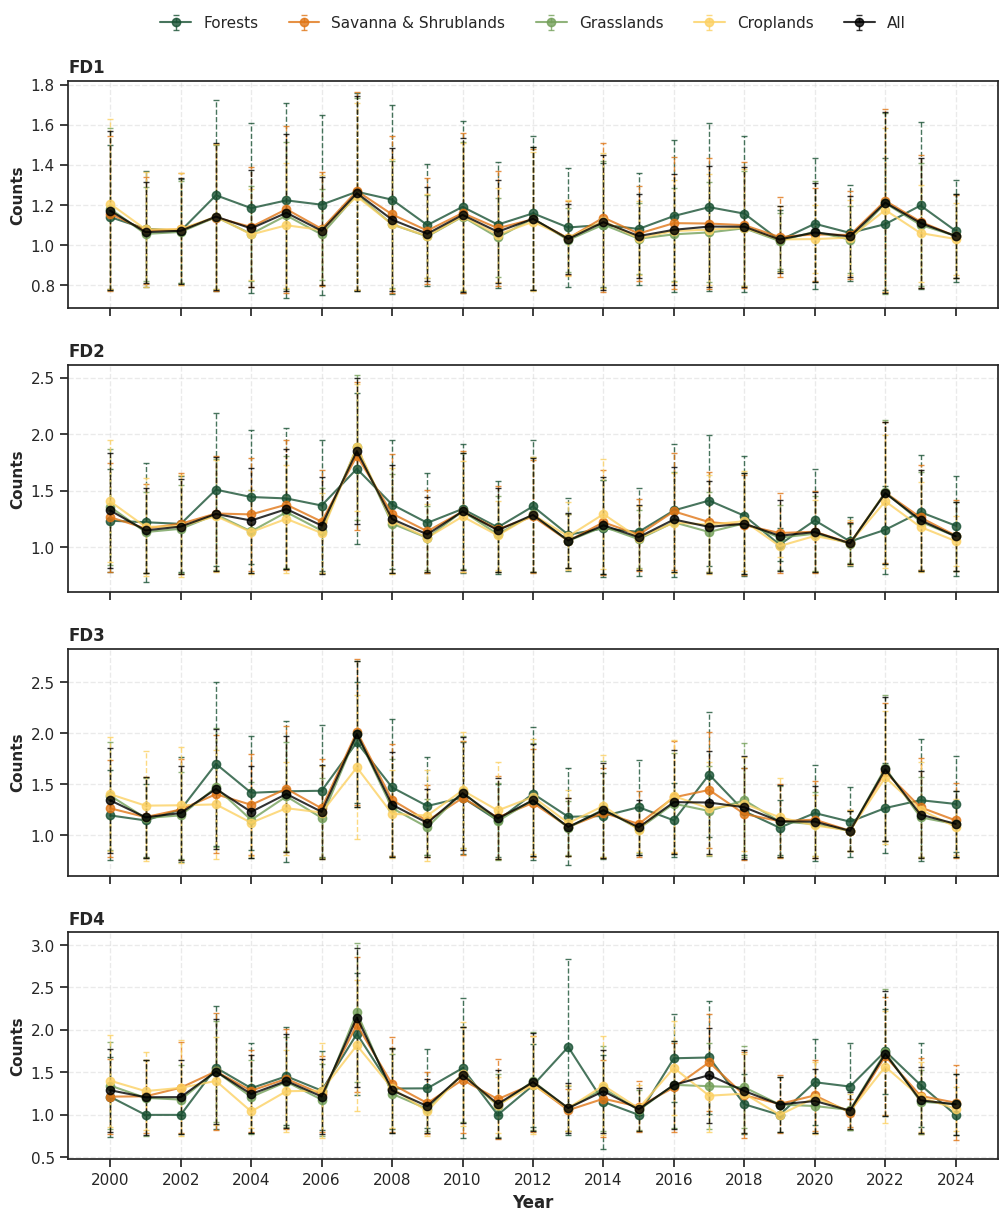

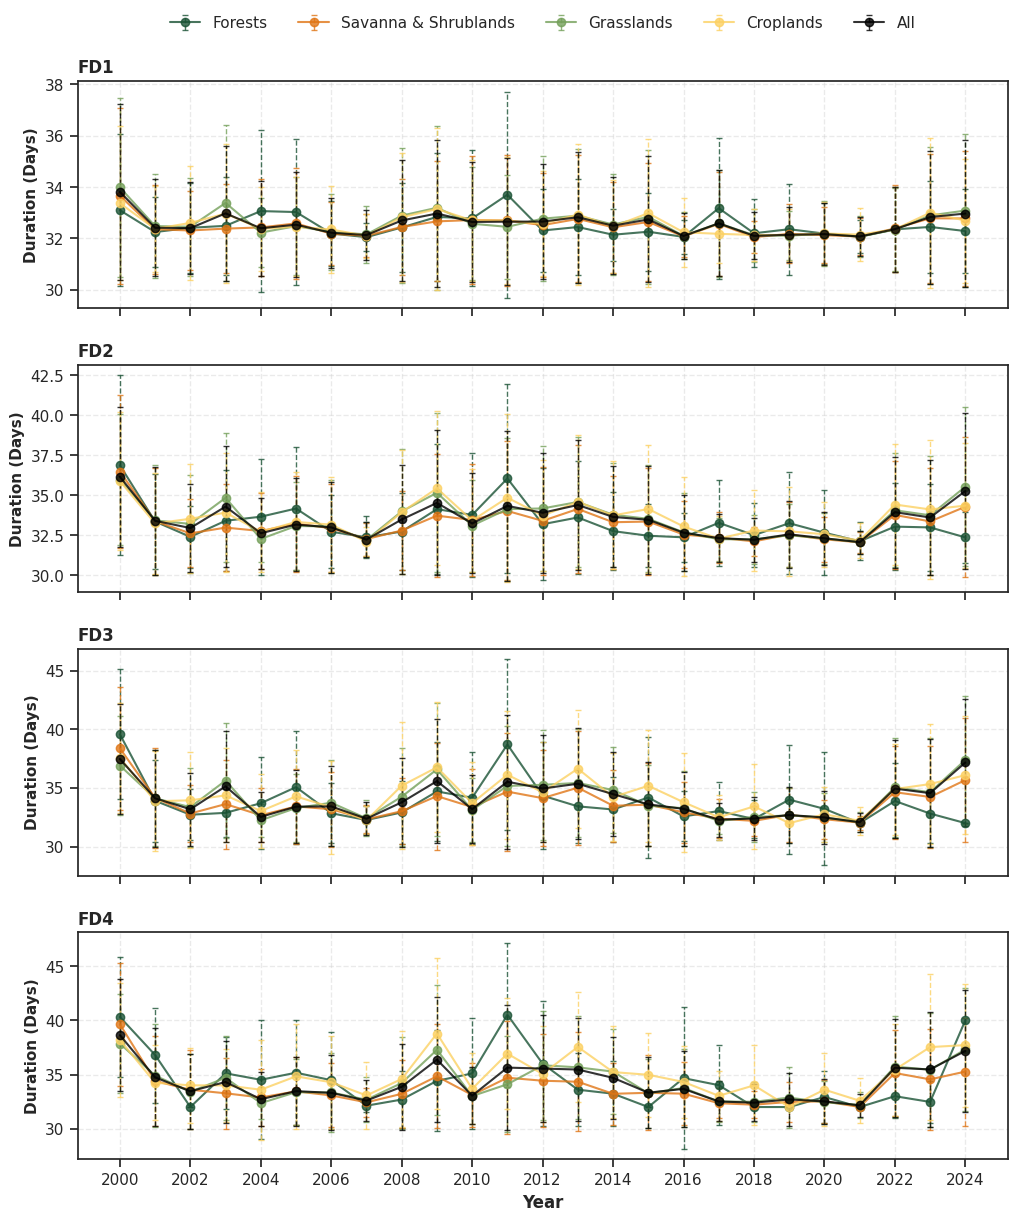

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# =========================================================================
# 2. DEFINING PLOTTING CONFIGURATIONS
# =========================================================================
fd_levels = [1, 2, 3, 4]
fd_titles = {1: 'FD1', 2: 'FD2', 3: 'FD3', 4: 'FD4'}
lc_order = ['Forests', 'Savanna & Shrublands', 'Grasslands', 'Croplands', 'All']

# Style options - Uniform markers and solid line configurations
palette = {
    'Forests': '#1a5235',
    'Savanna & Shrublands': '#e07616',
    'Grasslands': '#74a05a',
    'Croplands': '#fcd163',
    'All': '#000000'
}
markers = {
    'Forests': 'o',
    'Savanna & Shrublands': 'o',
    'Grasslands': 'o',
    'Croplands': 'o',
    'All': 'o'
}

sns.set_theme(style="ticks")

# =========================================================================
# PLOT 1: FLASH DROUGHT AVERAGE COUNTS (4 Rows x 1 Column)
# =========================================================================
fig, axes = plt.subplots(4, 1, figsize=(12, 14), sharex=True)

for idx, fd in enumerate(fd_levels):
    ax = axes[idx]
    df_fd = df_stats[df_stats['Max_Intensity'] == fd]

    for lc in lc_order:
        df_lc = df_fd[df_fd['LC_Group'] == lc].sort_values('Year')
        if df_lc.empty:
            continue

        # 1. Capture the structural components of the errorbar plot
        main_line, caps, bars = ax.errorbar(
            x=df_lc['Year'], y=df_lc['Count_Mean'], yerr=df_lc['Count_Std'],
            label=lc, color=palette[lc], marker=markers[lc],
            linestyle='-', linewidth=1.5, elinewidth=1, capsize=2, alpha=0.8
        )

        # 2. Force the vertical error bar lines to be dashed
        for bar in bars:
            bar.set_linestyle('--')

        # 3. Optional: If you also want the horizontal cap ticks to be dashed, uncomment below:
        # for cap in caps:
        #     cap.set_linestyle('--')

    ax.set_title(f"{fd_titles[fd]}", fontsize=12, weight='bold', loc='left')
    ax.set_ylabel('Counts', fontsize=11, weight='bold')
    ax.grid(True, linestyle='--', alpha=0.4)

# Set common X-axis parameters
axes[-1].set_xlabel('Year', fontsize=12, weight='bold')
axes[-1].set_xticks(range(2000, 2025, 2))

axes[0].legend(
    loc='upper center', bbox_to_anchor=(0.5, 1.35),
    ncol=5, frameon=True, facecolor='white', edgecolor='none', fontsize=11
)

plt.subplots_adjust(hspace=0.25)
plt.show()

# =========================================================================
# PLOT 2: FLASH DROUGHT AVERAGE DURATIONS (4 Rows x 1 Column)
# =========================================================================
fig, axes = plt.subplots(4, 1, figsize=(12, 14), sharex=True)

for idx, fd in enumerate(fd_levels):
    ax = axes[idx]
    df_fd = df_stats[df_stats['Max_Intensity'] == fd]

    for lc in lc_order:
        df_lc = df_fd[df_fd['LC_Group'] == lc].sort_values('Year')
        if df_lc.empty:
            continue

        # 1. Capture components
        main_line, caps, bars = ax.errorbar(
            x=df_lc['Year'], y=df_lc['Duration_Mean'], yerr=df_lc['Duration_Std'],
            label=lc, color=palette[lc], marker=markers[lc],
            linestyle='-', linewidth=1.5, elinewidth=1, capsize=2, alpha=0.8
        )

        # 2. Force vertical error bars to be dashed
        for bar in bars:
            bar.set_linestyle('--')

    ax.set_title(f"{fd_titles[fd]}", fontsize=12, weight='bold', loc='left')
    ax.set_ylabel('Duration (Days)', fontsize=11, weight='bold')
    ax.grid(True, linestyle='--', alpha=0.4)

# Set common X-axis parameters
axes[-1].set_xlabel('Year', fontsize=12, weight='bold')
axes[-1].set_xticks(range(2000, 2025, 2))

axes[0].legend(
    loc='upper center', bbox_to_anchor=(0.5, 1.35),
    ncol=5, frameon=True, facecolor='white', edgecolor='none', fontsize=11
)

plt.subplots_adjust(hspace=0.25)
plt.show()

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive



Spearman correlation: FD counts vs. duration
FD_Class  N_years  Spearman_rho  p_value
     FD1       25        0.0946   0.6528
     FD2       25        0.0462   0.8266
     FD3       25       -0.0577   0.7841
     FD4       25       -0.0515   0.8067
 Overall       25       -0.0215   0.9186


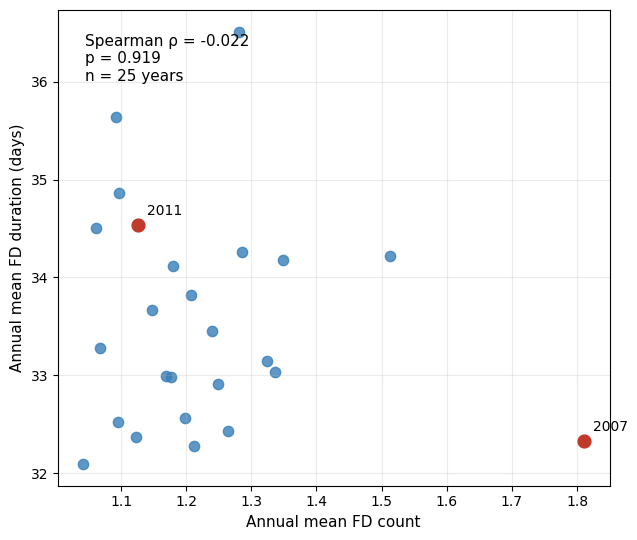

In [ ]:

# ============================================================
# REVIEWER COMMENT 8
# Spearman correlation: annual FD counts vs. mean duration
# Based on the same annual data used for Figures 7 and 8
# ============================================================

# Load existing Fig. 7 / Fig. 8 summary if needed
if 'df_stats' not in globals():
    df_stats = pd.read_csv(
        '/content/drive/MyDrive/GEE_Exports/FD_regional_summary.csv'
    )

# Regional data only; avoid mixing land-cover groups
regional = df_stats[
    (df_stats['LC_Group'] == 'All') &
    (df_stats['Year'].between(2000, 2024))
].copy()

regional = regional.dropna(
    subset=['Year', 'Max_Intensity',
            'Count_Mean', 'Duration_Mean']
)

results = []

# ------------------------------------------------------------
# A. Separate correlation for each FD intensity: FD1–FD4
# ------------------------------------------------------------
for fd in [1, 2, 3, 4]:

    data = regional[
        regional['Max_Intensity'] == fd
    ].sort_values('Year')

    # Each year is one observation
    data = data.drop_duplicates(subset='Year')

    if (len(data) >= 3 and
        data['Count_Mean'].nunique() > 1 and
        data['Duration_Mean'].nunique() > 1):

        rho, p = spearmanr(
            data['Count_Mean'],
            data['Duration_Mean']
        )
    else:
        rho, p = np.nan, np.nan

    results.append({
        'FD_Class': f'FD{fd}',
        'N_years': len(data),
        'Spearman_rho': rho,
        'p_value': p
    })

# ------------------------------------------------------------
# B. Overall annual relationship across FD1–FD4
#    Use annual averages, NOT 100 independent observations
# ------------------------------------------------------------
annual = (
    regional.groupby('Year', as_index=False)
    .agg(
        Count_Mean=('Count_Mean', 'mean'),
        Duration_Mean=('Duration_Mean', 'mean'),
        N_classes=('Max_Intensity', 'nunique')
    )
)

# Require all four intensity classes
annual = annual[annual['N_classes'] == 4].copy()

if (len(annual) >= 3 and
    annual['Count_Mean'].nunique() > 1 and
    annual['Duration_Mean'].nunique() > 1):

    rho_all, p_all = spearmanr(
        annual['Count_Mean'],
        annual['Duration_Mean']
    )
else:
    rho_all, p_all = np.nan, np.nan

results.append({
    'FD_Class': 'Overall',
    'N_years': len(annual),
    'Spearman_rho': rho_all,
    'p_value': p_all
})

# ------------------------------------------------------------
# C. Print and export results
# ------------------------------------------------------------
correlation_results = pd.DataFrame(results)

print('\nSpearman correlation: FD counts vs. duration')
print('=' * 65)
print(correlation_results.round(4).to_string(index=False))
print('=' * 65)

output_dir = '/content/drive/MyDrive/GEE_Exports/'
os.makedirs(output_dir, exist_ok=True)

correlation_results.to_csv(
    os.path.join(output_dir, 'FD_Count_Duration_Correlation.csv'),
    index=False
)

annual.to_csv(
    os.path.join(output_dir, 'FD_Annual_Count_Duration.csv'),
    index=False
)

# ------------------------------------------------------------
# D. Scatterplot: 25 annual observations
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6.5, 5.5))

ax.scatter(
    annual['Count_Mean'],
    annual['Duration_Mean'],
    s=55,
    color='#377eb8',
    alpha=0.8
)

# Label the two contrasting example years
for year in [2007, 2011]:
    subset = annual[annual['Year'] == year]
    if not subset.empty:
        x = subset['Count_Mean'].iloc[0]
        y = subset['Duration_Mean'].iloc[0]
        ax.scatter(x, y, color='#c0392b', s=85, zorder=3)
        ax.annotate(
            str(year), (x, y),
            xytext=(6, 7),
            textcoords='offset points',
            fontsize=10
        )

ax.text(
    0.05, 0.95,
    f"Spearman ρ = {rho_all:.3f}\n"
    f"p = {p_all:.3g}\n"
    f"n = {len(annual)} years",
    transform=ax.transAxes,
    va='top',
    fontsize=11
)

ax.set_xlabel('Annual mean FD count', fontsize=11)
ax.set_ylabel('Annual mean FD duration (days)', fontsize=11)
ax.grid(alpha=0.25)

plt.tight_layout()

fig.savefig(
    os.path.join(output_dir, 'FD_Count_Duration_Scatter.png'),
    dpi=300,
    bbox_inches='tight'
)
plt.show()


### Optional manuscript statistics — 2007 and 2011
Original cells 17–18. These are not plotting prerequisites, but support the manuscript narrative. Run after the annual summary above; they do not change the figures.


In [ ]:
# ============================================================
# Extract regional FD count and duration statistics for 2007 and 2011
# ============================================================

years_to_check = [2007, 2011]

summary_2007_2011 = (
    df_stats[
        (df_stats['LC_Group'] == 'All') &
        (df_stats['Year'].isin(years_to_check))
    ][
        ['Year', 'Max_Intensity',
         'Count_Mean', 'Count_Std',
         'Duration_Mean', 'Duration_Std',
         'Pixel_N']
    ]
    .sort_values(['Year', 'Max_Intensity'])
    .reset_index(drop=True)
)

print("\nRegional FD statistics for 2007 and 2011:")
print("=" * 90)
print(summary_2007_2011.to_string(index=False))
print("=" * 90)


Regional FD statistics for 2007 and 2011:
 Year  Max_Intensity  Count_Mean  Count_Std  Duration_Mean  Duration_Std  Pixel_N
 2007              1    1.259133   0.487868      32.128831      0.988238    83903
 2007              2    1.850380   0.647422      32.225789      1.068433   112525
 2007              3    1.990599   0.714017      32.372469      1.428732    14786
 2007              4    2.145609   0.813842      32.595579      1.877392     2232
 2011              1    1.066034   0.257511      32.651261      2.473590    26744
 2011              2    1.149893   0.374475      34.328584      4.679792     8913
 2011              3    1.162352   0.395695      35.525710      5.723342     1854
 2011              4    1.127778   0.395202      35.638519      5.741830      540


In [ ]:
# Optional: mean across FD1-FD4 for each year
overall_by_year = (
    summary_2007_2011
    .groupby('Year')
    .agg(
        Mean_Count_Across_Intensities=('Count_Mean', 'mean'),
        Mean_Duration_Across_Intensities=('Duration_Mean', 'mean')
    )
    .reset_index()
)

print("\nMean across FD1-FD4:")
print("=" * 70)
print(overall_by_year.to_string(index=False))


Mean across FD1-FD4:
 Year  Mean_Count_Across_Intensities  Mean_Duration_Across_Intensities
 2007                       1.811430                         32.330667
 2011                       1.126514                         34.536018


## Figure 9 — changes in GPP, AET and WUE
Original cell 1 extracts event responses and writes the CSV; cell 2 reads that CSV and plots the manuscript version. Skip extraction only if the existing CSV is the intended dataset. The original AET/WUE error-bar settings and temporal indexing have deliberately been preserved; see the notes before scientific revision.


In [ ]:
# 2. Configuration
EXPORT_FOLDER = '/content/drive/MyDrive/GEE_Exports'
# Define where you want to save the final extracted events dataframe
CSV_OUTPUT_PATH = '/content/drive/MyDrive/GEE_Exports/flash_drought_events_2000_2024.csv'

YEARS = list(range(2000, 2025))

IGBP_TO_GROUP = {
    1: 'Forests', 2: 'Forests', 3: 'Forests', 4: 'Forests', 5: 'Forests',
    6: 'Savannas & Shrublands', 7: 'Savannas & Shrublands',
    8: 'Savannas & Shrublands', 9: 'Savannas & Shrublands',
    10: 'Grasslands',
    12: 'Croplands', 14: 'Croplands'
}

def extract_events(fw_series, fi_series, gpp_series, aet_series, wue_series, lc_val):
    events = []
    n_steps = len(fw_series)

    if lc_val not in IGBP_TO_GROUP:
        return events

    lc_name = IGBP_TO_GROUP[lc_val]
    padded_fw = np.pad(fw_series, (1, 1), 'constant', constant_values=0)
    diff = np.diff(padded_fw)

    starts = np.where(diff == 1)[0]
    ends = np.where(diff == -1)[0] - 1

    for start_idx, end_idx in zip(starts, ends):
        pre_idx = start_idx - 4
        if pre_idx < 0:
            continue

        post_idx = end_idx + 1
        if post_idx >= n_steps:
            continue

        intensity = np.max(fi_series[start_idx:end_idx+1])
        if intensity == 0:
            continue

        delta_gpp = gpp_series[post_idx] - gpp_series[pre_idx]
        delta_aet = aet_series[post_idx] - aet_series[pre_idx]
        delta_wue = wue_series[post_idx] - wue_series[pre_idx]

        events.append({
            'LC_Name': lc_name,
            'Intensity': intensity,
            'Delta_GPP': delta_gpp,
            'Delta_AET': delta_aet,
            'Delta_WUE': delta_wue
        })

    return events

# Main Processing Loop
all_events = []

for yr in YEARS:
    fd_path = os.path.join(EXPORT_FOLDER, f'POS_FD_pixel_{yr}.tif')
    met_path = os.path.join(EXPORT_FOLDER, f'POS_Metrics_pixel_{yr}.tif')

    if not os.path.exists(fd_path) or not os.path.exists(met_path):
        print(f"Skipping {yr}: Files not found.")
        continue

    print(f"Processing year {yr}...")

    with rasterio.open(fd_path) as src_fd, rasterio.open(met_path) as src_met:
        fd_data = src_fd.read()
        met_data = src_met.read()

        n_steps = (fd_data.shape[0] - 1) // 2

        fw = fd_data[0:n_steps*2:2, :, :]
        fi = fd_data[1:n_steps*2:2, :, :]
        lc = fd_data[-1, :, :]

        gpp = met_data[0:n_steps*3:3, :, :]
        aet = met_data[1:n_steps*3:3, :, :]
        wue = met_data[2:n_steps*3:3, :, :]

        pixels_fw = fw.reshape(n_steps, -1).T
        pixels_fi = fi.reshape(n_steps, -1).T
        pixels_gpp = gpp.reshape(n_steps, -1).T
        pixels_aet = aet.reshape(n_steps, -1).T
        pixels_wue = wue.reshape(n_steps, -1).T
        pixels_lc = lc.flatten()

        valid_lc_mask = np.isin(pixels_lc, list(IGBP_TO_GROUP.keys()))

        pixels_fw = pixels_fw[valid_lc_mask]
        pixels_fi = pixels_fi[valid_lc_mask]
        pixels_gpp = pixels_gpp[valid_lc_mask]
        pixels_aet = pixels_aet[valid_lc_mask]
        pixels_wue = pixels_wue[valid_lc_mask]
        pixels_lc = pixels_lc[valid_lc_mask]

        for i in range(pixels_lc.shape[0]):
            if np.any(pixels_fw[i] == 1):
                pixel_events = extract_events(
                    pixels_fw[i], pixels_fi[i],
                    pixels_gpp[i], pixels_aet[i], pixels_wue[i],
                    pixels_lc[i]
                )
                all_events.extend(pixel_events)

# Convert to DataFrame, clean, and save to Drive
df_events = pd.DataFrame(all_events).dropna()
df_events.to_csv(CSV_OUTPUT_PATH, index=False)

print(f"\nSuccess! Total Flash Drought events extracted: {len(df_events)}")
print(f"Data saved to: {CSV_OUTPUT_PATH}")

Processing year 2000...
Processing year 2001...
Processing year 2002...
Processing year 2003...
Processing year 2004...
Processing year 2005...
Processing year 2006...
Processing year 2007...
Processing year 2008...
Processing year 2009...
Processing year 2010...
Processing year 2011...
Processing year 2012...
Processing year 2013...
Processing year 2014...
Processing year 2015...
Processing year 2016...
Processing year 2017...
Processing year 2018...
Processing year 2019...
Processing year 2020...
Processing year 2021...
Processing year 2022...
Processing year 2023...
Processing year 2024...

Success! Total Flash Drought events extracted: 2588305
Data saved to: /content/drive/MyDrive/GEE_Exports/flash_drought_events_2000_2024.csv


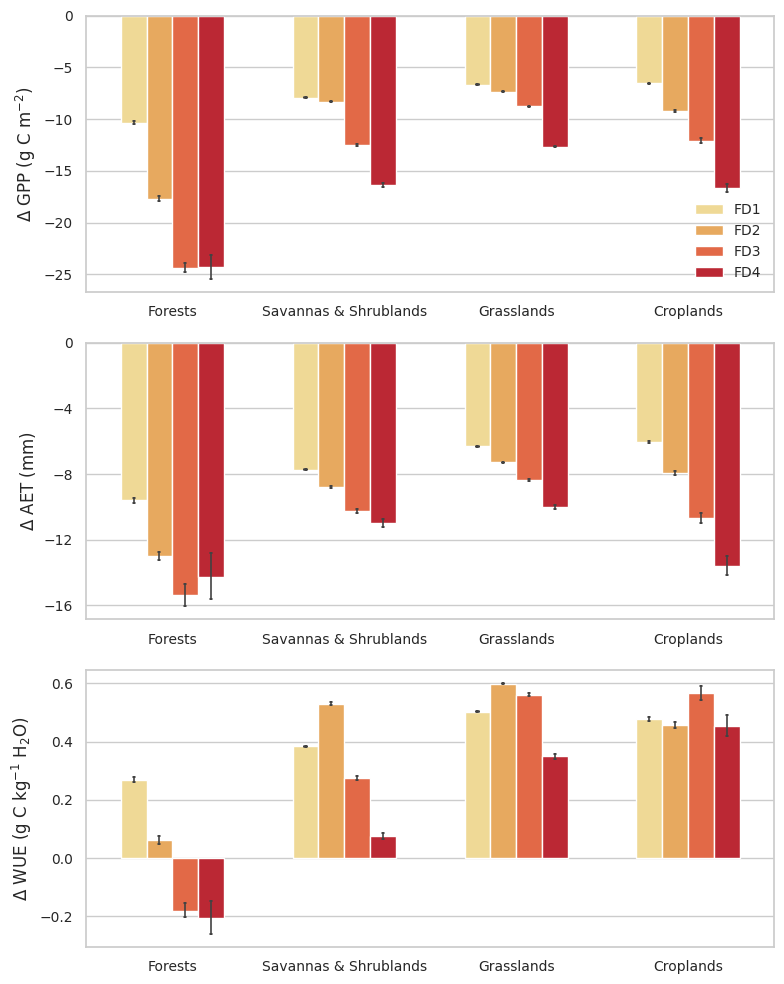

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# 1. Mount Google Drive
# Drive is mounted in Setup.

# 2. Read the pre-processed data directly from your Drive
CSV_OUTPUT_PATH = '/content/drive/MyDrive/GEE_Exports/flash_drought_events_2000_2024.csv'
df_events = pd.read_csv(CSV_OUTPUT_PATH)

# Replace the string in the dataframe so Seaborn aligns it properly with your order
# df_events['LC_Name'] = df_events['LC_Name'].replace('Savannas & Shrublands', 'Savannas &\nShrublands')

# 3. Setup and Execution of the Plot Code
# lc_order = ['Forests', 'Savannas &\nShrublands', 'Grasslands', 'Croplands']
lc_order = ['Forests', 'Savannas & Shrublands', 'Grasslands', 'Croplands']

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 1, figsize=(8, 10), sharey=False)

# Color palette mapped to intensities
palette = sns.color_palette("YlOrRd", 4)

# --- 1. Plot Delta GPP ---
sns.barplot(
    data=df_events, x='LC_Name', y='Delta_GPP', hue='Intensity',
    ax=axes[0], palette=palette, order=lc_order,errorbar='se',width=0.6,capsize=0.05,err_kws={'linewidth': 1.2}
)
axes[0].set_xlabel('')  # Remove x-axis label
axes[0].set_ylabel(r'$\Delta$ GPP ($\mathregular{g\ C\ m^{-2}}$)', fontsize=12)  # Theme on Y-axis + font size
axes[0].tick_params(axis='x', rotation=0, labelsize=10)         # X-tick font size
axes[0].tick_params(axis='y', labelsize=10)                      # Y-tick font size

# FIX: Get standard handles directly since capsize is turned off
handles, _ = axes[0].get_legend_handles_labels()

# Clean up the single remaining legend: custom labels, no title, no border box
axes[0].legend(
    handles=handles,                            # Uses the clean, native rectangle patches
    title=None,                                 # Removes the title
    labels=['FD1', 'FD2', 'FD3', 'FD4'],        # Overwrites the numeric values
    loc='lower right',
    fontsize=10,
    frameon=False                               # Removes the box frame border entirely
)

# --- 2. Plot Delta AET ---
sns.barplot(
    data=df_events, x='LC_Name', y='Delta_AET', hue='Intensity',
    ax=axes[1], palette=palette, order=lc_order,width=0.6,capsize=0.05,err_kws={'linewidth': 1.2}
)
axes[1].set_xlabel('')  # Remove x-axis label
axes[1].set_ylabel(r'$\Delta$ AET ($\mathregular{mm}$)', fontsize=12)          # Theme on Y-axis + font size
axes[1].tick_params(axis='x', rotation=0, labelsize=10)          # X-tick font size
axes[1].tick_params(axis='y', labelsize=10)                      # Y-tick font size
axes[1].get_legend().remove()
# CUSTOM Y-TICKS FOR AET: Spaced beautifully out down to -16
axes[1].set_yticks([0, -4, -8, -12, -16])

# --- 3. Plot Delta WUE ---
sns.barplot(
    data=df_events, x='LC_Name', y='Delta_WUE', hue='Intensity',
    ax=axes[2], palette=palette, order=lc_order, width=0.6,capsize=0.05,err_kws={'linewidth': 1.2}
)
axes[2].set_xlabel('')  # Remove x-axis label
# axes[2].set_ylabel(r'$\Delta$ WUE ($g\ C / kg\ H_2O$)', fontsize=12) # Theme on Y-axis + font size
axes[2].set_ylabel(r'$\Delta$ WUE ($\mathregular{g\ C\ kg^{-1}\ H_2O}$)', fontsize=12) # Theme on Y-axis + font size

axes[2].tick_params(axis='x', rotation=0, labelsize=10)              # X-tick font size
axes[2].tick_params(axis='y', labelsize=10)                          # Y-tick font size
axes[2].get_legend().remove()

plt.tight_layout()
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


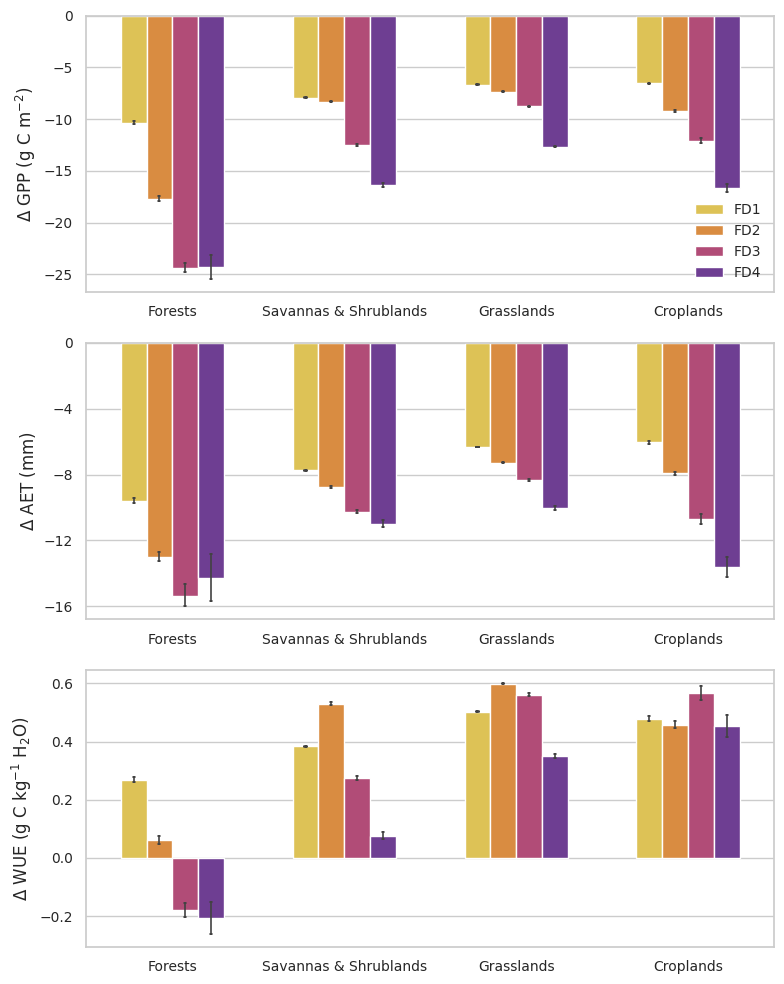

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

drive.mount('/content/drive')

# 1. Mount Google Drive
# Drive is mounted in Setup.

# 2. Read the pre-processed data directly from your Drive
CSV_OUTPUT_PATH = '/content/drive/MyDrive/GEE_Exports/flash_drought_events_2000_2024.csv'
df_events = pd.read_csv(CSV_OUTPUT_PATH)

# Replace the string in the dataframe so Seaborn aligns it properly with your order
# df_events['LC_Name'] = df_events['LC_Name'].replace('Savannas & Shrublands', 'Savannas &\nShrublands')

# 3. Setup and Execution of the Plot Code
# lc_order = ['Forests', 'Savannas &\nShrublands', 'Grasslands', 'Croplands']
lc_order = ['Forests', 'Savannas & Shrublands', 'Grasslands', 'Croplands']

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 1, figsize=(8, 10), sharey=False)

# Color palette mapped to FD intensities (FD1–FD4)
# Yellow → Orange-red → Red-purple → Dark purple
# palette = [
#     "#F3D56B",  # FD1: Moderate
#     "#E98C45",  # FD2: Severe
#     "#BD4C79",  # FD3: Extreme
#     "#67377C"   # FD4: Exceptional
# ]
# the below palette color is brighter than the above palette
palette = [
    "#F4D03F",  # FD1: Bright yellow
    "#F28C28",  # FD2: Vibrant orange
    "#C23B75",  # FD3: Magenta-red
    "#7030A0"   # FD4: Purple
]

# --- 1. Plot Delta GPP ---
sns.barplot(
    data=df_events, x='LC_Name', y='Delta_GPP', hue='Intensity',
    ax=axes[0], palette=palette, order=lc_order,errorbar='se',width=0.6,capsize=0.05,err_kws={'linewidth': 1.2}
)
axes[0].set_xlabel('')  # Remove x-axis label
axes[0].set_ylabel(r'$\Delta$ GPP ($\mathregular{g\ C\ m^{-2}}$)', fontsize=12)  # Theme on Y-axis + font size
axes[0].tick_params(axis='x', rotation=0, labelsize=10)         # X-tick font size
axes[0].tick_params(axis='y', labelsize=10)                      # Y-tick font size

# FIX: Get standard handles directly since capsize is turned off
handles, _ = axes[0].get_legend_handles_labels()

# Clean up the single remaining legend: custom labels, no title, no border box
axes[0].legend(
    handles=handles,                            # Uses the clean, native rectangle patches
    title=None,                                 # Removes the title
    labels=['FD1', 'FD2', 'FD3', 'FD4'],        # Overwrites the numeric values
    loc='lower right',
    fontsize=10,
    frameon=False                               # Removes the box frame border entirely
)

# --- 2. Plot Delta AET ---
sns.barplot(
    data=df_events, x='LC_Name', y='Delta_AET', hue='Intensity',
    ax=axes[1], palette=palette, order=lc_order,width=0.6,capsize=0.05,err_kws={'linewidth': 1.2}
)
axes[1].set_xlabel('')  # Remove x-axis label
axes[1].set_ylabel(r'$\Delta$ AET ($\mathregular{mm}$)', fontsize=12)          # Theme on Y-axis + font size
axes[1].tick_params(axis='x', rotation=0, labelsize=10)          # X-tick font size
axes[1].tick_params(axis='y', labelsize=10)                      # Y-tick font size
axes[1].get_legend().remove()
# CUSTOM Y-TICKS FOR AET: Spaced beautifully out down to -16
axes[1].set_yticks([0, -4, -8, -12, -16])

# --- 3. Plot Delta WUE ---
sns.barplot(
    data=df_events, x='LC_Name', y='Delta_WUE', hue='Intensity',
    ax=axes[2], palette=palette, order=lc_order, width=0.6,capsize=0.05,err_kws={'linewidth': 1.2}
)
axes[2].set_xlabel('')  # Remove x-axis label
# axes[2].set_ylabel(r'$\Delta$ WUE ($g\ C / kg\ H_2O$)', fontsize=12) # Theme on Y-axis + font size
axes[2].set_ylabel(r'$\Delta$ WUE ($\mathregular{g\ C\ kg^{-1}\ H_2O}$)', fontsize=12) # Theme on Y-axis + font size

axes[2].tick_params(axis='x', rotation=0, labelsize=10)              # X-tick font size
axes[2].tick_params(axis='y', labelsize=10)                          # Y-tick font size
axes[2].get_legend().remove()

plt.tight_layout()
plt.show()

In [3]:
# ============================================================
# Figure 9: Sample sizes (n) by land cover and FD intensity
# ============================================================

import pandas as pd

# Use the same dataframe as Figure 9
# df_events = pd.read_csv(CSV_OUTPUT_PATH)

lc_order = [
    'Forests',
    'Savannas & Shrublands',
    'Grasslands',
    'Croplands'
]

# Count valid observations separately for each variable
n_table = (
    df_events
    .groupby(['LC_Name', 'Intensity'])
    .agg(
        n_GPP=('Delta_GPP', 'count'),
        n_AET=('Delta_AET', 'count'),
        n_WUE=('Delta_WUE', 'count')
    )
    .reset_index()
)

# Order land-cover types
n_table['LC_Name'] = pd.Categorical(
    n_table['LC_Name'],
    categories=lc_order,
    ordered=True
)

n_table = n_table.sort_values(['LC_Name', 'Intensity'])

print("\nFigure 9: Sample sizes by land cover and FD intensity")
print("=" * 75)
print(n_table.to_string(index=False))
print("=" * 75)

# Compact table for reporting in the manuscript
n_wide = n_table.pivot(
    index='LC_Name',
    columns='Intensity',
    values='n_WUE'
)

print("\nSample sizes (n) for WUE:")
print(n_wide.to_string())

# Check whether sample sizes are identical across variables
same_n = (
    (n_table['n_GPP'] == n_table['n_AET']) &
    (n_table['n_AET'] == n_table['n_WUE'])
).all()

print("\nIdentical sample sizes for GPP, AET, and WUE:", same_n)


Figure 9: Sample sizes by land cover and FD intensity
              LC_Name  Intensity  n_GPP  n_AET  n_WUE
              Forests        1.0  45499  45499  45499
              Forests        2.0  17319  17319  17319
              Forests        3.0   2920   2920   2920
              Forests        4.0    639    639    639
Savannas & Shrublands        1.0 626830 626830 626830
Savannas & Shrublands        2.0 285473 285473 285473
Savannas & Shrublands        3.0  55559  55559  55559
Savannas & Shrublands        4.0  17657  17657  17657
           Grasslands        1.0 825214 825214 825214
           Grasslands        2.0 473995 473995 473995
           Grasslands        3.0 124008 124008 124008
           Grasslands        4.0  39853  39853  39853
            Croplands        1.0  42538  42538  42538
            Croplands        2.0  23237  23237  23237
            Croplands        3.0   5748   5748   5748
            Croplands        4.0   1816   1816   1816

Sample sizes (n) for WUE:


In [ ]:
# ================================================================
# Flash-drought GPP–AET relative responses
# Outputs: event data, summaries, paired tests, factorial tests,
#          publication figure (PNG/PDF), settings and package versions.
#
# Uses the same event/time indexing as your original notebook.
# Statistical unit: a pixel-level FD event, NOT an independent
# regional drought episode.
# ================================================================
%pip -q install rasterio pyproj statsmodels

import os, glob, re, json, warnings, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pyproj import Transformer
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from google.colab import drive

drive.mount("/content/drive")

# ----------------------- SETTINGS -------------------------------
DATA_DIR = "/content/drive/MyDrive/GEE_Exports"
BLOCK_KM = 10                 # sensitivity analysis: e.g. 5, 10, 20 km
OUT_DIR = os.path.join(DATA_DIR, f"WUE_relative_response_{BLOCK_KM:g}km")
os.makedirs(OUT_DIR, exist_ok=True)

YEARS = range(2000, 2025)

# Original notebook alignment:
PRE_OFFSET = 4               # pre index = first marked FD window - 4
POST_OFFSET = 1              # post index = last marked FD window + 1
# Confirm these offsets and the FD/metrics date alignment using GEE code.
# This cell cannot establish date alignment from band positions alone.

MIN_GPP_PRE = 0.0             # exclude baselines <= this value
MIN_AET_PRE = 0.0             # choose higher thresholds only with justification
MIN_BLOCKS = 20               # conservative screening rule, not a guarantee
ALPHA = 0.05

LC_MAP = {
    **{i: "Forests" for i in [1, 2, 3, 4, 5]},
    **{i: "Savanna & Shrublands" for i in [6, 7, 8, 9]},
    10: "Grasslands", 12: "Croplands", 14: "Croplands"
}
LC_ORDER = ["Forests", "Savanna & Shrublands", "Grasslands", "Croplands"]
FD_ORDER = ["FD1", "FD2", "FD3", "FD4"]

# ---------------- EXTRACT PAIRED EVENT VALUES --------------------
# Original file conventions:
# FD:      fw_0, fi_0, fw_1, fi_1, ..., LC_class
# Metrics: GPP_0, AET_0, WUE_0, GPP_1, AET_1, WUE_1, ...
# Only GPP and AET are used below.
chunks, extraction_log = [], []
reference_grid = None

for year in YEARS:
    fd_path = os.path.join(DATA_DIR, f"POS_FD_pixel_{year}.tif")
    met_path = os.path.join(DATA_DIR, f"POS_Metrics_pixel_{year}.tif")
    if not (os.path.isfile(fd_path) and os.path.isfile(met_path)):
        extraction_log.append({"year": year, "status": "missing input"})
        continue

    print(f"Extracting {year}...")
    with rasterio.open(fd_path) as fd, rasterio.open(met_path) as met:
        if fd.crs is None:
            raise ValueError(f"{year}: FD raster has no CRS.")
        if (fd.shape != met.shape or fd.crs != met.crs
                or not fd.transform.almost_equals(met.transform)):
            raise ValueError(f"{year}: FD and metrics grids do not align.")

        grid = (fd.shape, fd.crs.to_string(), tuple(fd.transform))
        if reference_grid is None:
            reference_grid = grid
        elif grid != reference_grid:
            raise ValueError("Annual grids differ; stable pixel IDs need regridding.")

        # Select the required bands by name; ignore unrelated extra bands.
        def find_indexed_bands(src, pattern, label):
            found = {}
            for band_number, description in enumerate(
                src.descriptions, start=1
            ):
                match = re.search(pattern, description or "", flags=re.I)
                if match:
                    time_index = int(match.group(1))
                    if time_index in found:
                        raise ValueError(
                            f"{year}: duplicate {label} index {time_index}"
                        )
                    found[time_index] = band_number

            if not found:
                raise ValueError(f"{year}: no {label} bands found.")
            return found

        fw_bands = find_indexed_bands(fd, r"^fw(\d+)$", "fw")
        fi_bands = find_indexed_bands(fd, r"^fi(\d+)$", "fi")
        gpp_bands = find_indexed_bands(met, r"_gpp_(\d+)$", "GPP")
        aet_bands = find_indexed_bands(met, r"_aet_(\d+)$", "AET")

        fd_indices = sorted(fw_bands)
        flux_indices = sorted(gpp_bands)

        if fd_indices != sorted(fi_bands):
            raise ValueError(f"{year}: fw and fi indices differ.")
        if flux_indices != sorted(aet_bands):
            raise ValueError(f"{year}: GPP and AET indices differ.")

        # The downstream event code uses zero-based sequential indices.
        if fd_indices != list(range(len(fd_indices))):
            raise ValueError(f"{year}: FD indices are not consecutive from 0.")
        if flux_indices != list(range(len(flux_indices))):
            raise ValueError(f"{year}: flux indices are not consecutive from 0.")

        nt = len(fd_indices)
        n_flux = len(flux_indices)
        if n_flux < nt:
            raise ValueError(f"{year}: fewer flux observations than FD windows.")

        # Confirm that paired GPP/AET bands carry matching date labels.
        for index in flux_indices:
            gpp_name = met.descriptions[gpp_bands[index] - 1]
            aet_name = met.descriptions[aet_bands[index] - 1]
            gpp_date = re.sub(r"_gpp_\d+$", "", gpp_name, flags=re.I)
            aet_date = re.sub(r"_aet_\d+$", "", aet_name, flags=re.I)
            if gpp_date != aet_date:
                raise ValueError(
                    f"{year}: GPP/AET dates differ at index {index}."
                )

        lc_matches = [
            i for i, name in enumerate(fd.descriptions, start=1)
            if (name or "").lower() == "lc_class"
        ]
        if len(lc_matches) != 1:
            raise ValueError(f"{year}: expected exactly one LC_class band.")

        def read_float(src, bands):
            return (
                src.read(bands, masked=True)
                .astype("float64")
                .filled(np.nan)
            )

        h, w = fd.shape
        fw = read_float(
            fd, [fw_bands[i] for i in fd_indices]
        ).reshape(nt, -1)
        fi = read_float(
            fd, [fi_bands[i] for i in fd_indices]
        ).reshape(nt, -1)
        lc = read_float(fd, lc_matches[0]).ravel()

        gpp = read_float(
            met, [gpp_bands[i] for i in flux_indices]
        ).reshape(n_flux, -1)
        aet = read_float(
            met, [aet_bands[i] for i in flux_indices]
        ).reshape(n_flux, -1)

        print(
            f"  Selected {nt} FD windows and {n_flux} paired flux observations."
        )

        active = fw == 1
        changes = np.diff(
            np.pad(active.astype(np.int8), ((1, 1), (0, 0))), axis=0
        )
        candidate_pixels = np.flatnonzero(
            active.any(axis=0) & np.isin(lc, list(LC_MAP))
        )
        records = []
        skipped_edge = skipped_invalid = 0

        for pixel in candidate_pixels:
            starts = np.flatnonzero(changes[:, pixel] == 1)
            ends = np.flatnonzero(changes[:, pixel] == -1) - 1

            for start, end in zip(starts, ends):
                pre, post = start - PRE_OFFSET, end + POST_OFFSET
                if pre < 0 or post >= nt:
                    skipped_edge += 1
                    continue

                # Reject events with missing FD/intensity observations.
                intensity_values = fi[start:end + 1, pixel]
                if (not np.isfinite(fw[pre:post + 1, pixel]).all()
                        or not np.isfinite(intensity_values).all()):
                    skipped_invalid += 1
                    continue
                intensity = intensity_values.max()
                if intensity not in [1, 2, 3, 4]:
                    skipped_invalid += 1
                    continue

                row, col = divmod(int(pixel), w)
                records.append((
                    f"{year}_{pixel}_{start}", str(pixel), year, row, col,
                    LC_MAP[int(lc[pixel])], f"FD{int(intensity)}",
                    start, end, pre, post,
                    gpp[pre, pixel], gpp[post, pixel],
                    aet[pre, pixel], aet[post, pixel]
                ))

        part = pd.DataFrame(records, columns=[
            "event_id", "pixel_id", "year", "row", "col",
            "land_cover", "intensity", "fd_start_index", "fd_end_index",
            "pre_index", "post_index",
            "GPP_pre", "GPP_post", "AET_pre", "AET_post"
        ])
        if len(part):
            x, y = rasterio.transform.xy(
                fd.transform, part["row"], part["col"], offset="center"
            )
            # Equal-area projected coordinates in metres; fixed grid origin.
            transform = Transformer.from_crs(fd.crs, "EPSG:5070", always_xy=True)
            east, north = transform.transform(x, y)
            bx = np.floor(np.asarray(east) / (BLOCK_KM * 1000)).astype(int)
            by = np.floor(np.asarray(north) / (BLOCK_KM * 1000)).astype(int)
            part["spatial_block"] = [
                f"{i}_{j}" for i, j in zip(bx, by)
            ]
            chunks.append(part)

        extraction_log.append({
            "year": year, "status": "processed",
            "candidate_events": len(part),
            "excluded_window_edges": skipped_edge,
            "excluded_invalid_fd": skipped_invalid
        })

pd.DataFrame(extraction_log).to_csv(
    os.path.join(OUT_DIR, "extraction_log.csv"), index=False
)
if not chunks:
    raise ValueError("No events extracted. Check paths, bands and time offsets.")

events = pd.concat(chunks, ignore_index=True)
flux_columns = ["GPP_pre", "GPP_post", "AET_pre", "AET_post"]

# Apply a common paired-event mask to all three response metrics.
finite = np.isfinite(events[flux_columns]).all(axis=1)
valid = (
    finite
    & (events.GPP_pre > MIN_GPP_PRE)
    & (events.AET_pre > MIN_AET_PRE)
    & (events.GPP_post >= 0)
    & (events.AET_post > 0)
)
excluded = events.loc[~valid].copy()
excluded.to_csv(os.path.join(OUT_DIR, "excluded_events.csv"), index=False)
events = events.loc[valid].copy()
if events.empty:
    raise ValueError("No valid paired events after baseline/nodata filtering.")

events["GPP_pct"] = 100 * (events.GPP_post / events.GPP_pre - 1)
events["AET_pct"] = 100 * (events.AET_post / events.AET_pre - 1)
events["D_pp"] = events.GPP_pct - events.AET_pct  # percentage points

# Exact WUE percentage response; D itself is not ΔWUE%.
events["WUE_pct"] = 100 * (
    (events.GPP_post / events.AET_post)
    / (events.GPP_pre / events.AET_pre) - 1
)
assert np.allclose(
    events.WUE_pct,
    events.D_pp / (1 + events.AET_pct / 100),
    rtol=1e-8, atol=1e-8
)

# Optional exact additive log-ratio decomposition:
# ln(WUEpost/WUEpre) = ln(GPPpost/GPPpre) - ln(AETpost/AETpre).
# Undefined for zero post-event GPP; retain NaN for those events.
events["log_GPP_contribution"] = np.nan
positive_gpp = events.GPP_post > 0
events.loc[positive_gpp, "log_GPP_contribution"] = np.log(
    events.loc[positive_gpp, "GPP_post"]
    / events.loc[positive_gpp, "GPP_pre"]
)
events["log_AET_contribution"] = -np.log(events.AET_post / events.AET_pre)
events["log_WUE_change"] = (
    events.log_GPP_contribution + events.log_AET_contribution
)
events.to_csv(
    os.path.join(OUT_DIR, "event_relative_responses.csv.gz"),
    index=False, compression="gzip"
)

# ------------ DESCRIPTIVE SUMMARY + CLUSTER-ROBUST SE -------------
# Each mean is event-weighted. Spatial blocks are inference clusters,
# including all years, repeated pixels and events within each block.
# SE_independent is descriptive only; do not use it for inference here.
def cluster_mean_result(values, blocks):
    values = np.asarray(values, dtype=float)
    groups = pd.factorize(blocks)[0]
    B = len(np.unique(groups))
    mean = values.mean()
    if B < MIN_BLOCKS or len(values) < 2:
        return mean, np.nan, np.nan, np.nan, np.nan, B
    fit = sm.OLS(values, np.ones((len(values), 1))).fit(
        cov_type="cluster",
        cov_kwds={"groups": groups, "use_correction": True},
        use_t=True
    )
    se = float(fit.bse[0])
    if not np.isfinite(se) or se <= 0:
        return mean, se, np.nan, np.nan, np.nan, B
    critical = stats.t.ppf(0.975, B - 1)
    p = 2 * stats.t.sf(abs(mean / se), B - 1)
    return mean, se, mean-critical*se, mean+critical*se, p, B

summary_rows, paired_rows = [], []
metrics = ["GPP_pct", "AET_pct", "D_pp", "WUE_pct"]
for lc in LC_ORDER:
    for intensity in FD_ORDER:
        g = events[
            (events.land_cover == lc) & (events.intensity == intensity)
        ]
        for metric in metrics:
            if g.empty:
                summary_rows.append({
                    "land_cover": lc, "intensity": intensity,
                    "metric": metric, "n_events": 0
                })
                continue
            x = g[metric]
            mean, se, low, high, p, B = cluster_mean_result(
                x, g.spatial_block
            )
            q = x.quantile([.025, .25, .5, .75, .975])
            summary_rows.append({
                "land_cover": lc, "intensity": intensity, "metric": metric,
                "n_events": len(g), "n_pixels": g.pixel_id.nunique(),
                "n_years": g.year.nunique(), "n_blocks": B,
                "mean": mean, "SD": x.std(ddof=1),
                "SE_independent_DO_NOT_USE_FOR_INFERENCE": x.sem(),
                "SE_spatial_cluster": se,
                "CI95_low": low, "CI95_high": high,
                "min": x.min(), "p2_5": q.loc[.025],
                "q25": q.loc[.25], "median": q.loc[.5],
                "q75": q.loc[.75], "p97_5": q.loc[.975], "max": x.max()
            })
            if metric == "D_pp":
                paired_rows.append({
                    "land_cover": lc, "intensity": intensity,
                    "n_events": len(g), "n_blocks": B,
                    "mean_paired_difference_pp": mean,
                    "SE_spatial_cluster": se,
                    "CI95_low": low, "CI95_high": high, "p_raw": p,
                    "test": "paired difference; spatial-cluster robust t",
                    "status": "tested" if np.isfinite(p)
                              else "insufficient blocks or degenerate variance"
                })

summary = pd.DataFrame(summary_rows)
paired_tests = pd.DataFrame(paired_rows)
paired_tests["p_Holm"] = np.nan
ok = paired_tests.p_raw.notna()
if ok.any():
    paired_tests.loc[ok, "p_Holm"] = multipletests(
        paired_tests.loc[ok, "p_raw"], method="holm"
    )[1]
summary.to_csv(os.path.join(OUT_DIR, "group_summary.csv"), index=False)
paired_tests.to_csv(os.path.join(OUT_DIR, "paired_tests.csv"), index=False)

# ---------------- FACTORIAL MODEL FOR D -------------------------
# Year fixed effects adjust common year-specific mean shifts.
# Spatial-block robust covariance allows arbitrary dependence inside
# a block across pixels/events/years. It does NOT remove dependence
# spanning blocks or prove the chosen block width is sufficient.
model_data = events.copy()
model_data["land_cover"] = pd.Categorical(
    model_data.land_cover, categories=LC_ORDER
)
model_data["intensity"] = pd.Categorical(
    model_data.intensity, categories=FD_ORDER
)
counts = pd.crosstab(model_data.land_cover, model_data.intensity).reindex(
    index=LC_ORDER, columns=FD_ORDER, fill_value=0
)
model_status = "not fitted"
if (counts.to_numpy() == 0).any():
    model_status = "Skipped: missing land-cover × intensity combinations."
elif model_data.spatial_block.nunique() < MIN_BLOCKS:
    model_status = "Skipped: too few spatial blocks."
else:
    ordinary = smf.ols(
        "D_pp ~ C(land_cover, Sum) * C(intensity, Sum) + C(year)",
        data=model_data
    ).fit()
    X = ordinary.model.exog
    if np.linalg.matrix_rank(X) < X.shape[1]:
        model_status = "Skipped: rank-deficient model."
    else:
        fitted = ordinary.get_robustcov_results(
            cov_type="cluster",
            groups=pd.factorize(model_data.spatial_block)[0],
            use_correction=True, df_correction=True, use_t=True
        )
        with open(os.path.join(OUT_DIR, "D_model.txt"), "w") as f:
            f.write(fitted.summary().as_text())

        ci = fitted.conf_int()
        pd.DataFrame({
            "term": ordinary.model.exog_names,
            "coefficient": fitted.params, "SE_cluster": fitted.bse,
            "CI95_low": ci[:, 0], "CI95_high": ci[:, 1],
            "p_raw": fitted.pvalues
        }).to_csv(os.path.join(OUT_DIR, "D_model_coefficients.csv"),
                  index=False)

        # Joint tests:
        # 1) interaction
        # 2) all terms involving land cover (main + interaction)
        # 3) all terms involving intensity (main + interaction)
        names = ordinary.model.exog_names
        hypotheses = {
            "land_cover_by_intensity_interaction":
                [i for i, n in enumerate(names)
                 if "land_cover" in n and "intensity" in n],
            "any_land_cover_difference_including_interaction":
                [i for i, n in enumerate(names) if "land_cover" in n],
            "any_intensity_difference_including_interaction":
                [i for i, n in enumerate(names) if "intensity" in n]
        }
        tests = []
        for label, indices in hypotheses.items():
            R = np.eye(len(names))[indices]
            covariance = R @ fitted.cov_params() @ R.T
            if np.linalg.matrix_rank(covariance) < len(indices):
                tests.append({"hypothesis": label, "p_raw": np.nan,
                              "status": "singular contrast covariance"})
                continue
            result = fitted.wald_test(R, use_f=True, scalar=True)
            tests.append({
                "hypothesis": label, "F": float(result.statistic),
                "df_num": float(result.df_num),
                "df_denom": float(result.df_denom),
                "p_raw": float(result.pvalue), "status": "tested"
            })
        factorial_tests = pd.DataFrame(tests)
        factorial_tests["p_Holm"] = np.nan
        ok = factorial_tests.p_raw.notna()
        if ok.any():
            factorial_tests.loc[ok, "p_Holm"] = multipletests(
                factorial_tests.loc[ok, "p_raw"], method="holm"
            )[1]
        factorial_tests.to_csv(
            os.path.join(OUT_DIR, "D_factorial_tests.csv"), index=False
        )
        model_status = "fitted; inspect residuals and block-size sensitivity"



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Extracting 2000...
  Selected 42 FD windows and 46 paired flux observations.
Extracting 2001...
  Selected 46 FD windows and 46 paired flux observations.
Extracting 2002...
  Selected 46 FD windows and 46 paired flux observations.
Extracting 2003...
  Selected 46 FD windows and 46 paired flux observations.
Extracting 2004...
  Selected 46 FD windows and 46 paired flux observations.
Extracting 2005...
  Selected 46 FD windows and 46 paired flux observations.
Extracting 2006...
  Selected 46 FD windows and 46 paired flux observations.
Extracting 2007...
  Selected 46 FD windows and 46 paired flux observations.
Extracting 2008...
  Selected 46 FD windows and 46 paired flux observations.
Extracting 2009...
  Selected 46 FD windows and 46 paired flux observations.
Extracting 2010...
  Selected 46 FD windows and 46 paired flux observations.
Extracting 2011...
  Sel

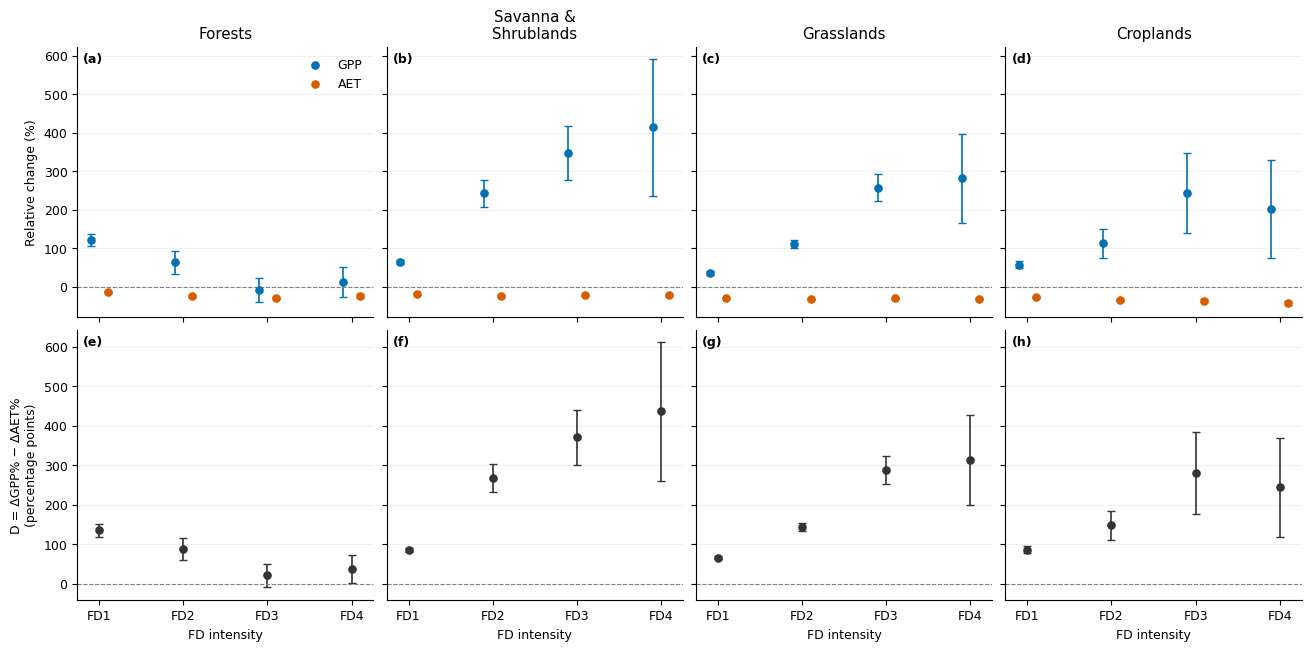

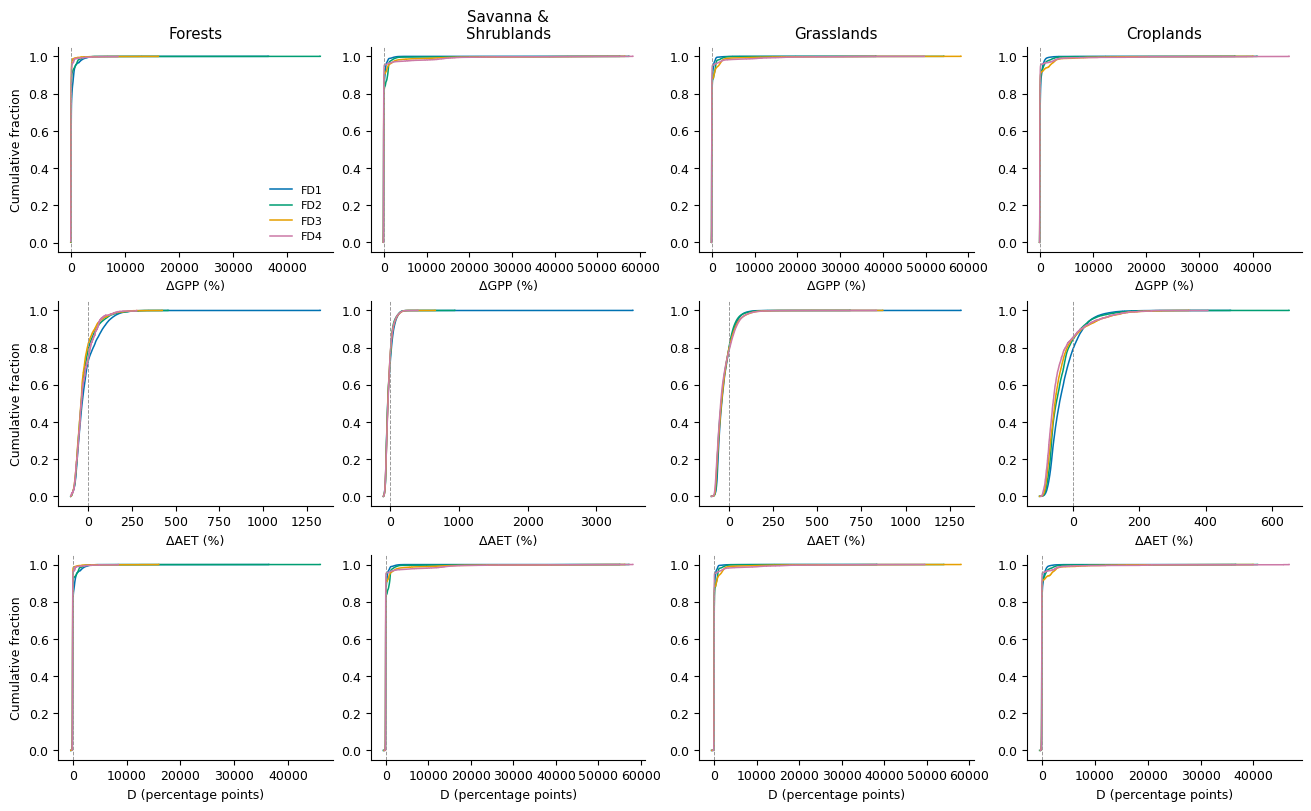


Saved to: /content/drive/MyDrive/GEE_Exports/WUE_relative_response_10km
Valid pixel-events: 2588059
Excluded for flux/baseline validity: 442
Factorial model: fitted; inspect residuals and block-size sensitivity

Paired comparisons (Holm-adjusted across available groups):


,land_cover,intensity,n_events,n_blocks,mean_paired_difference_pp,SE_spatial_cluster,CI95_low,CI95_high,p_raw,test,status,p_Holm
0,Forests,FD1,45498,261,135.007021,8.290393,118.682161,151.331882,1.399096e-41,paired difference; spatial-cluster robust t,tested,1.399096e-40
1,Forests,FD2,17318,260,87.766830,14.607501,59.002242,116.531418,6.326495e-09,paired difference; spatial-cluster robust t,tested,4.428546e-08
2,Forests,FD3,2920,215,20.527345,15.365246,-9.759265,50.813955,1.829815e-01,paired difference; spatial-cluster robust t,tested,1.829815e-01
3,Forests,FD4,639,133,36.388767,18.246029,0.296318,72.481216,4.817519e-02,paired difference; spatial-cluster robust t,tested,9.635037e-02
4,Savanna & Shrublands,FD1,626825,661,84.211596,2.752126,78.807618,89.615575,1.073112e-128,paired difference; spatial-cluster robust t,tested,1.716979e-127
5,Savanna & Shrublands,FD2,285440,661,266.920161,17.666850,232.230156,301.610166,1.641321e-44,paired difference; spatial-cluster robust t,tested,1.805454e-43
6,Savanna & Shrublands,FD3,55548,653,370.090544,35.563065,300.258586,439.922502,1.438917e-23,paired difference; spatial-cluster robust t,tested,1.295026e-22
7,Savanna & Shrublands,FD4,17655,609,436.013021,89.150794,260.932149,611.093893,1.287664e-06,paired difference; spatial-cluster robust t,tested,5.150654e-06
8,Grasslands,FD1,825205,713,65.569324,2.212626,61.225273,69.913376,2.352924e-126,paired difference; spatial-cluster robust t,tested,3.529386e-125
9,Grasslands,FD2,473922,713,143.058007,5.046808,133.149602,152.966411,6.558766e-119,paired difference; spatial-cluster robust t,tested,9.182272e-118



Interpretation: D is NOT the magnitude of WUE percentage change.
Exactly, ΔWUE% = D / (1 + ΔAET%/100).
For positive pre/post AET and positive baseline GPP, its sign matches D.
Group mean ΔWUE% must be averaged event by event, as done here.


In [ ]:
# ------------------- PUBLICATION FIGURE -------------------------
# Row 1: GPP and AET mean percentage changes with cluster-robust 95% CI.
# Row 2: D mean and cluster-robust 95% CI.
# Missing CI indicates inadequate independent blocks, not zero uncertainty.
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "savefig.dpi": 600
})
fig, axes = plt.subplots(
    2, 4, figsize=(13, 6.4), sharex=True, sharey="row",
    constrained_layout=True
)
colors = {"GPP_pct": "#0072B2", "AET_pct": "#D55E00"}
labels = {"GPP_pct": "GPP", "AET_pct": "AET"}
x = np.arange(4)

def plot_estimates(ax, subset, metric, offset, color, label=None):
    tab = subset[subset.metric == metric].set_index("intensity").reindex(FD_ORDER)
    mean = tab["mean"].to_numpy(float)
    se = tab["SE_spatial_cluster"].to_numpy(float)
    lo = tab["CI95_low"].to_numpy(float)
    hi = tab["CI95_high"].to_numpy(float)
    ax.scatter(x+offset, mean, s=27, color=color, label=label, zorder=3)
    mask = np.isfinite(mean) & np.isfinite(se) & np.isfinite(lo) & np.isfinite(hi)
    ax.errorbar(
        (x+offset)[mask], mean[mask],
        yerr=np.vstack([mean[mask]-lo[mask], hi[mask]-mean[mask]]),
        fmt="none", ecolor=color, elinewidth=1.2, capsize=3
    )

for col, lc in enumerate(LC_ORDER):
    sub = summary[summary.land_cover == lc]
    top, bottom = axes[0, col], axes[1, col]
    for metric, offset in [("GPP_pct", -.10), ("AET_pct", .10)]:
        plot_estimates(top, sub, metric, offset, colors[metric], labels[metric])
    plot_estimates(bottom, sub, "D_pp", 0, "#333333")
    top.set_title(lc.replace(" & ", " &\n"))
    for row, ax in enumerate([top, bottom]):
        ax.axhline(0, color=".5", lw=.8, ls="--")
        ax.grid(axis="y", alpha=.18)
        ax.set_axisbelow(True)
        ax.text(.02, .98, f"({chr(97 + row*4 + col)})",
                transform=ax.transAxes, va="top", fontweight="bold")
        ax.set_xticks(x, FD_ORDER)
    bottom.set_xlabel("FD intensity")
axes[0, 0].set_ylabel("Relative change (%)")
axes[1, 0].set_ylabel("D = ΔGPP% − ΔAET%\n(percentage points)")
axes[0, 0].legend(frameon=False, loc="best")
fig.savefig(os.path.join(OUT_DIR, "GPP_AET_relative_response.png"),
            bbox_inches="tight", dpi=600)
fig.savefig(os.path.join(OUT_DIR, "GPP_AET_relative_response.pdf"),
            bbox_inches="tight")
plt.show()

# Distribution figure: event-level ECDFs; no subsampling.
fig, axes = plt.subplots(3, 4, figsize=(13, 8), constrained_layout=True)
fd_colors = ["#0072B2", "#009E73", "#E69F00", "#CC79A7"]
for col, lc in enumerate(LC_ORDER):
    for row, metric in enumerate(["GPP_pct", "AET_pct", "D_pp"]):
        ax = axes[row, col]
        for fd_class, color in zip(FD_ORDER, fd_colors):
            values = events.loc[
                (events.land_cover == lc) & (events.intensity == fd_class),
                metric
            ].to_numpy()
            if len(values):
                unique, count = np.unique(values, return_counts=True)
                ax.step(unique, np.cumsum(count)/len(values), where="post",
                        color=color, lw=1.1, label=fd_class)
        ax.axvline(0, color=".6", lw=.7, ls="--")
        ax.set_xlabel({
            "GPP_pct": "ΔGPP (%)", "AET_pct": "ΔAET (%)",
            "D_pp": "D (percentage points)"
        }[metric])
        if col == 0:
            ax.set_ylabel("Cumulative fraction")
        if row == 0:
            ax.set_title(lc.replace(" & ", " &\n"))
axes[0, 0].legend(frameon=False, fontsize=8)
fig.savefig(os.path.join(OUT_DIR, "response_distributions.pdf"),
            bbox_inches="tight")
plt.show()

settings = {
    "block_km": BLOCK_KM, "pre_offset": PRE_OFFSET,
    "post_offset": POST_OFFSET,
    "minimum_GPP_baseline": MIN_GPP_PRE,
    "minimum_AET_baseline": MIN_AET_PRE,
    "minimum_blocks_for_testing": MIN_BLOCKS,
    "valid_events": len(events), "excluded_flux_events": len(excluded),
    "model_status": model_status,
    "versions": {
        p: importlib.metadata.version(p)
        for p in ["numpy", "pandas", "scipy", "statsmodels",
                  "matplotlib", "rasterio", "pyproj"]
    }
}
with open(os.path.join(OUT_DIR, "analysis_settings.json"), "w") as f:
    json.dump(settings, f, indent=2)

caption = """
Event-level relative changes in GPP and AET (upper panels) and their paired
difference D = ΔGPP% − ΔAET% (lower panels), stratified by land-cover type
and flash-drought intensity. Points represent event-weighted means;
error bars represent 95% confidence intervals using spatial-block
cluster-robust standard errors. Repeated observations within each spatial
block are clustered across years. D is measured in percentage points.
Positive D indicates a greater proportional AET reduction, or a smaller
proportional AET increase, relative to GPP. It describes the balance between
carbon uptake and total evapotranspiration and does not demonstrate
physiological optimization. Event, pixel, year and block counts are provided
in group_summary.csv. Block width and time-index alignment must be
validated before final manuscript use.
""".strip()
with open(os.path.join(OUT_DIR, "figure_caption.txt"), "w") as f:
    f.write(caption)

print("\nSaved to:", OUT_DIR)
print("Valid pixel-events:", len(events))
print("Excluded for flux/baseline validity:", len(excluded))
print("Factorial model:", model_status)
print("\nPaired comparisons (Holm-adjusted across available groups):")
display(paired_tests)
print(
    "\nInterpretation: D is NOT the magnitude of WUE percentage change.\n"
    "Exactly, ΔWUE% = D / (1 + ΔAET%/100).\n"
    "For positive pre/post AET and positive baseline GPP, its sign matches D.\n"
    "Group mean ΔWUE% must be averaged event by event, as done here."
)

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

BASE = Path("/content/drive/MyDrive/GEE_Exports")
filename = "event_relative_responses.csv.gz"

if not BASE.is_dir():
    raise FileNotFoundError(
        "GEE_Exports is not accessible. Check that you mounted "
        "the same Google account used for the analysis."
    )

matches = sorted(BASE.rglob(filename))

if len(matches) == 1:
    NEW_FILE = str(matches[0])
    NEW_DIR = str(matches[0].parent)
    OLD_FILE = str(BASE / "flash_drought_events_2000_2024.csv")

    print("Found saved event data:")
    print(NEW_FILE)
    print(f"Size: {matches[0].stat().st_size / 1024**2:.2f} MB")
    print("Original Figure 9 CSV exists:", Path(OLD_FILE).is_file())

elif len(matches) > 1:
    print("Multiple saved datasets found. Select the one used for your new figure:")
    for p in matches:
        print(f"{p}  ({p.stat().st_size / 1024**2:.2f} MB)")

else:
    print("No matching CSV found under:", BASE)
    print("Check the mounted Google account and the file's location in Drive.")
    print("Do not rerun extraction yet.")

Mounted at /content/drive
Found saved event data:
/content/drive/MyDrive/GEE_Exports/WUE_relative_response_10km/event_relative_responses.csv.gz
Size: 214.26 MB
Original Figure 9 CSV exists: True


In [ ]:
import os
import numpy as np
import pandas as pd
from IPython.display import display

BASE = "/content/drive/MyDrive/GEE_Exports"
NEW_DIR = os.path.join(BASE, "WUE_relative_response_10km")

OLD_FILE = os.path.join(BASE, "flash_drought_events_2000_2024.csv")
NEW_FILE = os.path.join(NEW_DIR, "event_relative_responses.csv.gz")

keys = ["land_cover", "intensity"]

def normalize_land_cover(s):
    return s.replace({"Savannas & Shrublands": "Savanna & Shrublands"})

# ------------------------------------------------------------
# A. Recompute BOTH types of change on the SAME new events.
# ------------------------------------------------------------
parts = []

for chunk in pd.read_csv(
    NEW_FILE,
    usecols=["land_cover", "intensity", "GPP_pre", "GPP_post", "GPP_pct"],
    chunksize=50000
):
    chunk["land_cover"] = normalize_land_cover(chunk["land_cover"])

    pre = chunk["GPP_pre"].to_numpy(float)
    post = chunk["GPP_post"].to_numpy(float)
    saved_pct = chunk["GPP_pct"].to_numpy(float)

    if not (
        np.isfinite(pre).all()
        and np.isfinite(post).all()
        and (pre > 0).all()
    ):
        raise ValueError("Saved new data contain invalid GPP baselines/values.")

    delta = post - pre
    pct = 100 * delta / pre

    chunk["delta"] = delta
    chunk["pct"] = pct
    chunk["increase"] = (delta > 0).astype(int)
    chunk["over100"] = (pct > 100).astype(int)
    chunk["positive_pct"] = np.maximum(pct, 0)
    chunk["negative_pct"] = np.minimum(pct, 0)
    chunk["pre_if_increase"] = np.where(delta > 0, pre, 0)
    chunk["pre_if_nonincrease"] = np.where(delta <= 0, pre, 0)
    chunk["formula_mismatch"] = (
        ~np.isclose(saved_pct, pct, rtol=1e-7, atol=1e-7)
    ).astype(int)

    parts.append(chunk.groupby(keys).agg(
        N_new=("delta", "size"),
        sum_pre=("GPP_pre", "sum"),
        sum_delta=("delta", "sum"),
        sum_pct=("pct", "sum"),
        n_increase=("increase", "sum"),
        n_over100=("over100", "sum"),
        sum_positive_pct=("positive_pct", "sum"),
        sum_negative_pct=("negative_pct", "sum"),
        sum_pre_increase=("pre_if_increase", "sum"),
        sum_pre_nonincrease=("pre_if_nonincrease", "sum"),
        formula_mismatches=("formula_mismatch", "sum")
    ))

if not parts:
    raise ValueError("New event CSV contains no records.")

new = pd.concat(parts).groupby(level=keys).sum()
result = pd.DataFrame(index=new.index)

result["N_new"] = new.N_new.astype(int)
result["new_mean_absolute_change"] = new.sum_delta / new.N_new
result["new_mean_event_change_pct"] = new.sum_pct / new.N_new

# Different estimand, shown ONLY to diagnose aggregation:
# 100 * (mean(post) - mean(pre)) / mean(pre).
result["change_in_group_mean_pct"] = 100 * new.sum_delta / new.sum_pre

result["events_with_GPP_increase_pct"] = 100 * new.n_increase / new.N_new
result["events_with_increase_over100pct_pct"] = 100 * new.n_over100 / new.N_new

# These two columns sum to new_mean_event_change_pct.
result["positive_events_contribution_to_mean_pct"] = (
    new.sum_positive_pct / new.N_new
)
result["negative_events_contribution_to_mean_pct"] = (
    new.sum_negative_pct / new.N_new
)
result["mean_pre_GPP_increasing_events"] = (
    new.sum_pre_increase / new.n_increase.replace(0, np.nan)
)
result["mean_pre_GPP_nonincreasing_events"] = (
    new.sum_pre_nonincrease
    / (new.N_new - new.n_increase).replace(0, np.nan)
)
result["saved_percentage_formula_mismatches"] = (
    new.formula_mismatches.astype(int)
)

# ------------------------------------------------------------
# B. Compare with the CSV used by the original Figure 9.
# ------------------------------------------------------------
old_parts = []

for chunk in pd.read_csv(
    OLD_FILE,
    usecols=["LC_Name", "Intensity", "Delta_GPP"],
    chunksize=50000
):
    chunk["land_cover"] = normalize_land_cover(chunk["LC_Name"])
    numeric_intensity = pd.to_numeric(chunk["Intensity"], errors="coerce")
    keep = numeric_intensity.isin([1, 2, 3, 4])
    chunk = chunk.loc[keep].copy()
    chunk["intensity"] = (
        "FD" + numeric_intensity.loc[keep].astype(int).astype(str)
    )
    if not np.isfinite(chunk["Delta_GPP"]).all():
        raise ValueError("Original CSV contains nonfinite GPP differences.")

    old_parts.append(chunk.groupby(keys).agg(
        N_old=("Delta_GPP", "size"),
        old_sum_delta=("Delta_GPP", "sum")
    ))

if old_parts:
    old = pd.concat(old_parts).groupby(level=keys).sum()
    old["old_Fig9_mean_absolute_change"] = old.old_sum_delta / old.N_old
    result = result.join(
        old[["N_old", "old_Fig9_mean_absolute_change"]], how="outer"
    )

result = result.reset_index()
output = os.path.join(NEW_DIR, "GPP_sign_diagnostic.csv")
result.to_csv(output, index=False)

main_columns = [
    "land_cover", "intensity",
    "N_old", "N_new",
    "old_Fig9_mean_absolute_change",
    "new_mean_absolute_change",
    "new_mean_event_change_pct",
    "change_in_group_mean_pct",
    "events_with_GPP_increase_pct",
    "events_with_increase_over100pct_pct",
    "saved_percentage_formula_mismatches"
]
with pd.option_context("display.max_columns", None, "display.max_rows", None):
    display(result[[c for c in main_columns if c in result]].round(4))

print("Full diagnostic saved to:", output)

,land_cover,intensity,N_old,N_new,old_Fig9_mean_absolute_change,new_mean_absolute_change,new_mean_event_change_pct,change_in_group_mean_pct,events_with_GPP_increase_pct,events_with_increase_over100pct_pct,saved_percentage_formula_mismatches
0,Croplands,FD1,42538,42537,-6.5509,-6.5517,57.2127,-24.0523,30.6980,16.2047,0
1,Croplands,FD2,23237,23233,-9.1991,-9.2069,112.2638,-32.5909,21.3274,10.1580,0
2,Croplands,FD3,5748,5745,-12.0666,-12.0896,243.2072,-35.9486,20.4178,9.4343,0
3,Croplands,FD4,1816,1816,-16.6632,-16.6632,202.6270,-43.3952,13.9868,4.9559,0
4,Forests,FD1,45499,45498,-10.3511,-10.3518,121.1832,-24.9404,31.5355,20.7416,0
5,Forests,FD2,17319,17318,-17.6748,-17.6767,63.1162,-36.7885,20.0081,9.8799,0
6,Forests,FD3,2920,2920,-24.3396,-24.3396,-8.2967,-44.6467,12.8425,2.7740,0
7,Forests,FD4,639,639,-24.2801,-24.2801,12.5082,-42.9210,17.5274,4.5383,0
8,Grasslands,FD1,825214,825205,-6.6751,-6.6754,35.8166,-23.4331,28.0058,13.6922,0
9,Grasslands,FD2,473995,473922,-7.3565,-7.3628,110.7278,-25.3987,25.6382,13.9519,0


Full diagnostic saved to: /content/drive/MyDrive/GEE_Exports/WUE_relative_response_10km/GPP_sign_diagnostic.csv


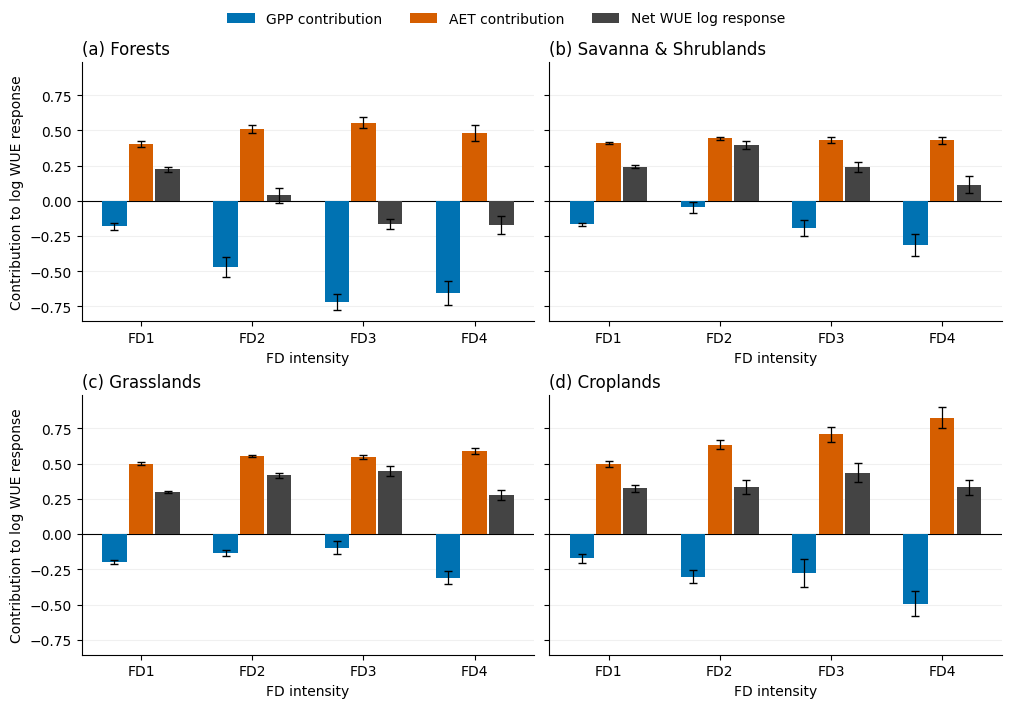

Saved to: /content/drive/MyDrive/GEE_Exports/WUE_relative_response_10km/WUE_log_decomposition
The two component means add exactly to the net mean. Their confidence-interval endpoints are not additive.
Exclusions below are additional exclusions from the SAVED dataset; earlier extraction exclusions remain in the original audit.


In [ ]:
# ================================================================
# Exact WUE log-ratio decomposition using SAVED event data
# No raster extraction. Reads CSV in chunks to limit RAM.
# ================================================================
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Use the path already discovered in your previous diagnostic.
# Otherwise try the original default location.
candidate = globals().get(
    "NEW_FILE",
    "/content/drive/MyDrive/GEE_Exports/"
    "WUE_relative_response_10km/event_relative_responses.csv.gz"
)
EVENT_FILE = Path(candidate)

if not EVENT_FILE.is_file():
    raise FileNotFoundError(
        "Set EVENT_FILE to your saved event_relative_responses.csv.gz. "
        "Do not rerun extraction."
    )

OUTPUT = EVENT_FILE.parent / "WUE_log_decomposition"
OUTPUT.mkdir(parents=True, exist_ok=True)

LC_ORDER = [
    "Forests", "Savanna & Shrublands", "Grasslands", "Croplands"
]
FD_ORDER = ["FD1", "FD2", "FD3", "FD4"]

# Reuse the spatial blocks recorded during event extraction.
# This does not redefine or validate their width.
MIN_BLOCKS = 20
CHUNK_SIZE = 50000

METRICS = [
    "GPP_contribution",
    "AET_contribution",
    "Net_WUE_response"
]
group_keys = ["land_cover", "intensity"]
block_keys = group_keys + ["spatial_block"]

required = [
    "land_cover", "intensity", "spatial_block",
    "GPP_pre", "GPP_post", "AET_pre", "AET_post"
]

block_totals = None
audit_parts = []

for chunk in pd.read_csv(
    EVENT_FILE, usecols=required, chunksize=CHUNK_SIZE
):
    chunk["land_cover"] = chunk["land_cover"].replace({
        "Savannas & Shrublands": "Savanna & Shrublands"
    })

    if chunk[group_keys + ["spatial_block"]].isna().any().any():
        raise ValueError("Missing group or spatial-block identifiers.")
    if not chunk["land_cover"].isin(LC_ORDER).all():
        raise ValueError("Unexpected land-cover labels.")
    if not chunk["intensity"].isin(FD_ORDER).all():
        raise ValueError("Unexpected intensity labels.")

    flux_cols = ["GPP_pre", "GPP_post", "AET_pre", "AET_post"]
    values = chunk[flux_cols].to_numpy(dtype=float)

    # A single common event set ensures exact additivity of group means.
    valid = np.isfinite(values).all(axis=1) & (values > 0).all(axis=1)

    audit = chunk[group_keys].copy()
    audit["n_saved_events"] = 1
    audit["n_used_for_log"] = valid.astype(int)
    audit["n_excluded_for_log"] = (~valid).astype(int)
    audit_parts.append(audit.groupby(group_keys).sum())

    data = chunk.loc[valid].copy()
    if data.empty:
        continue

    # Difference of logs avoids overflow from dividing very small values.
    log_gpp = (
        np.log(data["GPP_post"].to_numpy(float))
        - np.log(data["GPP_pre"].to_numpy(float))
    )
    log_aet = (
        np.log(data["AET_post"].to_numpy(float))
        - np.log(data["AET_pre"].to_numpy(float))
    )

    data["GPP_contribution"] = log_gpp
    data["AET_contribution"] = -log_aet
    data["Net_WUE_response"] = log_gpp - log_aet

    # Save compact sufficient statistics, not all event rows in memory.
    specification = {"n": ("Net_WUE_response", "size")}
    for metric in METRICS:
        data[metric + "_sq"] = data[metric] ** 2
        specification[metric + "_sum"] = (metric, "sum")
        specification[metric + "_sumsq"] = (metric + "_sq", "sum")

    current = data.groupby(block_keys).agg(**specification)
    block_totals = (
        current if block_totals is None
        else block_totals.add(current, fill_value=0)
    )

if block_totals is None:
    raise ValueError("No events with positive finite pre/post GPP and AET.")

audit_table = pd.concat(audit_parts).groupby(level=group_keys).sum()
audit_table["excluded_pct_of_saved_events"] = (
    100 * audit_table.n_excluded_for_log / audit_table.n_saved_events
)
audit_table.to_csv(OUTPUT / "log_decomposition_sample_audit.csv")

block_totals.to_csv(OUTPUT / "log_decomposition_block_sums.csv")

# ================================================================
# Means, descriptive SD, and spatial-cluster SE / 95% CI
#
# All events from a given spatial block, across all years, are kept
# together. Assumes residual independence BETWEEN spatial blocks.
# ================================================================
rows = []

for (lc, fd_class), group in block_totals.groupby(level=group_keys):
    n = group["n"].to_numpy(float)
    N = int(n.sum())
    B = len(group)

    for metric in METRICS:
        sums = group[metric + "_sum"].to_numpy(float)
        sumsq = group[metric + "_sumsq"].sum()
        mean = sums.sum() / N

        sd = (
            np.sqrt(max(0.0, (sumsq - N * mean**2) / (N - 1)))
            if N > 1 else np.nan
        )

        se = ci_low = ci_high = np.nan
        if B >= MIN_BLOCKS:
            # Cluster sandwich variance for an intercept-only mean.
            residual_sums = sums - n * mean
            variance = (
                B / (B - 1) * np.sum(residual_sums**2) / N**2
            )
            se = np.sqrt(max(0.0, variance))
            if se > 0:
                critical = stats.t.ppf(0.975, B - 1)
                ci_low = mean - critical * se
                ci_high = mean + critical * se

        rows.append({
            "land_cover": lc,
            "intensity": fd_class,
            "metric": metric,
            "n_pixel_events": N,
            "n_spatial_blocks": B,
            "mean_log_contribution": mean,
            "SD": sd,
            "SE_spatial_cluster": se,
            "CI95_low": ci_low,
            "CI95_high": ci_high
        })

log_summary = pd.DataFrame(rows)

# Verify exact additivity of the group means.
wide = log_summary.pivot(
    index=group_keys,
    columns="metric",
    values="mean_log_contribution"
)
assert np.allclose(
    wide["GPP_contribution"] + wide["AET_contribution"],
    wide["Net_WUE_response"],
    rtol=1e-10, atol=1e-10
)

log_summary.to_csv(OUTPUT / "WUE_log_decomposition_summary.csv", index=False)

# Optional back-transformation of the NET response:
# This is a geometric-mean WUE ratio, not the arithmetic mean ΔWUE%.
net = log_summary[
    log_summary.metric == "Net_WUE_response"
].copy()
net["geometric_mean_WUE_ratio"] = np.exp(net["mean_log_contribution"])
net["geometric_mean_WUE_change_pct"] = (
    100 * np.expm1(net["mean_log_contribution"])
)
net.to_csv(OUTPUT / "net_geometric_WUE_response.csv", index=False)

# ================================================================
# FIGURE: two component contributions + their net sum
# Bars are dimensionless natural-log contributions, NOT percentages.
# ================================================================
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig, axes = plt.subplots(
    2, 2, figsize=(10, 7), sharey=True, constrained_layout=True
)

styles = [
    ("GPP_contribution", -0.24, "#0072B2", "GPP contribution"),
    ("AET_contribution",  0.00, "#D55E00", "AET contribution"),
    ("Net_WUE_response", 0.24, "#444444", "Net WUE log response")
]
x = np.arange(len(FD_ORDER))

for panel, (ax, lc) in enumerate(zip(axes.flat, LC_ORDER)):
    sub = log_summary[log_summary.land_cover == lc]

    for metric, offset, color, label in styles:
        table = (
            sub[sub.metric == metric]
            .set_index("intensity")
            .reindex(FD_ORDER)
        )
        mean = table["mean_log_contribution"].to_numpy(float)
        low = table["CI95_low"].to_numpy(float)
        high = table["CI95_high"].to_numpy(float)

        ax.bar(
            x + offset, mean, width=0.22,
            color=color, label=label, zorder=3
        )

        good = np.isfinite(mean) & np.isfinite(low) & np.isfinite(high)
        ax.errorbar(
            (x + offset)[good], mean[good],
            yerr=np.vstack([
                mean[good] - low[good],
                high[good] - mean[good]
            ]),
            fmt="none", ecolor="black",
            capsize=3, elinewidth=0.9, zorder=4
        )

    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(x, FD_ORDER)
    ax.set_title(f"({chr(97 + panel)}) {lc}", loc="left")
    ax.set_xlabel("FD intensity")
    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)

for ax in axes[:, 0]:
    ax.set_ylabel("Contribution to log WUE response")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center",
           ncol=3, frameon=False)

fig.savefig(
    OUTPUT / "WUE_log_decomposition.png",
    dpi=600, bbox_inches="tight"
)
fig.savefig(
    OUTPUT / "WUE_log_decomposition.pdf",
    bbox_inches="tight"
)
plt.show()

print("Saved to:", OUTPUT)
print(
    "The two component means add exactly to the net mean. "
    "Their confidence-interval endpoints are not additive."
)
print(
    "Exclusions below are additional exclusions from the SAVED dataset; "
    "earlier extraction exclusions remain in the original audit."
)
# display(audit_table.reset_index())
# display(wide.reset_index().round(4))